# Radar de Startups — versión simplificada para Google Colab

Conserva los datasets, filtros, matching, los tres mapas, pipeline y web Flask. Simplifica imports repetidos y una función de normalización duplicada. El mapa utiliza un `merge` explícito entre startups e inversores agrupados por país (ISO3), seguido de otro merge con Natural Earth. Ejecutar **Entorno de ejecución → Ejecutar todas**.


In [ ]:
import importlib.util
import subprocess
import sys

# Instalar solo si falta una dependencia (funciona en Colab y Jupyter).
for paquete in ["pandas", "matplotlib", "flask", "geopandas"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", paquete])

import json
import os
import io
import re
import base64
import threading
from datetime import datetime
from urllib.parse import quote_plus, urlsplit
import urllib.request

import geopandas as gpd

import pandas as pd
import matplotlib
# matplotlib.use("Agg")  # para generar imágenes sin abrir ventanas
import matplotlib.pyplot as plt
from flask import Flask, request, redirect, url_for, render_template, Response
from jinja2 import DictLoader
from werkzeug.serving import run_simple

print("Librerías listas ✅")


Librerías listas ✅


In [ ]:
CARPETA_DATOS = 'datos_startup_intelligence'
os.makedirs(CARPETA_DATOS, exist_ok=True)

def descargar_fuente(url, nombre):
    destino = os.path.join(CARPETA_DATOS, nombre)
    if not os.path.exists(destino):
        print('Descargando:', nombre)
        with urllib.request.urlopen(url, timeout=90) as respuesta:
            contenido = respuesta.read()
        temporal = destino + '.tmp'
        with open(temporal, 'wb') as archivo:
            archivo.write(contenido)
        os.replace(temporal, destino)
    return destino

# Para actualizar una fuente, borrá su archivo de esta carpeta y repetí la carga.


## 1. Datasets, cruce histórico, motor de matching y mapas del notebook nuevo

Se conservan estas etapas. La tabla deduplicada se llama `startups_cruce` para distinguirla
de la tabla preparada para la web. Los datos se guardan localmente durante la sesión.

In [ ]:
# =====================================================
# STARTUP INTELLIGENCE
# ETAPA 1: CONECTAR STARTUPS CON INVERSORES
# =====================================================

import time
import unicodedata

# 1. CARGAR DATASET DE STARTUPS

url = f"https://raw.githubusercontent.com/yigitmeteozcan/startups/main/data/all.json?t={int(time.time())}"

df = pd.read_json(descargar_fuente(url, 'startups.json'))

print("STARTUPS CARGADAS:", len(df))


Descargando: startups.json
STARTUPS CARGADAS: 22436


In [ ]:
# 2. CARGAR DATASET DE INVERSIONES DE CRUNCHBASE

url_vc = (
    "https://raw.githubusercontent.com/"
    "dsagal/crunchbase-october-2013/master/"
    "crunchbase-investments.csv"
)

vc = pd.read_csv(
    descargar_fuente(url_vc, 'crunchbase.csv'),
    encoding="latin1",
    low_memory=False
)

print("REGISTROS DE INVERSION:", len(vc))
print("INVERSORES DISTINTOS:", vc["investor_name"].nunique())

print("\nCOLUMNAS DEL DATASET DE INVERSORES:")
print(vc.columns.tolist())

display(vc.head(10))


Descargando: crunchbase.csv
REGISTROS DE INVERSION: 52870
INVERSORES DISTINTOS: 10465

COLUMNAS DEL DATASET DE INVERSORES:
['company_permalink', 'company_name', 'company_category_code', 'company_country_code', 'company_state_code', 'company_region', 'company_city', 'investor_permalink', 'investor_name', 'investor_category_code', 'investor_country_code', 'investor_state_code', 'investor_region', 'investor_city', 'funding_round_type', 'funded_at', 'funded_month', 'funded_quarter', 'funded_year', 'raised_amount_usd']


,company_permalink,company_name,company_category_code,company_country_code,company_state_code,company_region,company_city,investor_permalink,investor_name,investor_category_code,investor_country_code,investor_state_code,investor_region,investor_city,funding_round_type,funded_at,funded_month,funded_quarter,funded_year,raised_amount_usd
0,/company/advercar,AdverCar,advertising,USA,CA,SF Bay,San Francisco,/company/1-800-flowers-com,1-800-FLOWERS.COM,NaN,USA,NY,New York,New York,series-a,2012-10-30,2012-10,2012-Q4,2012.0,2000000.0
1,/company/launchgram,LaunchGram,news,USA,CA,SF Bay,Mountain View,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,other,2012-01-23,2012-01,2012-Q1,2012.0,20000.0
2,/company/utap,uTaP,messaging,USA,NaN,United States - Other,NaN,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,other,2012-01-01,2012-01,2012-Q1,2012.0,20000.0
3,/company/zoopshop,ZoopShop,software,USA,OH,Columbus,columbus,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,angel,2012-02-15,2012-02,2012-Q1,2012.0,20000.0
4,/company/efuneral,eFuneral,web,USA,OH,Cleveland,Cleveland,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,other,2011-09-08,2011-09,2011-Q3,2011.0,20000.0
5,/company/tackk,Tackk,web,USA,OH,Cleveland,Cleveland,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,other,2012-02-01,2012-02,2012-Q1,2012.0,20000.0
6,/company/acclaimd,Acclaimd,analytics,USA,OH,Columbus,Columbus,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,angel,2012-06-01,2012-06,2012-Q2,2012.0,20000.0
7,/company/acclaimd,Acclaimd,analytics,USA,OH,Columbus,Columbus,/company/10xelerator,10Xelerator,finance,USA,OH,Columbus,Columbus,angel,2012-08-07,2012-08,2012-Q3,2012.0,70000.0
8,/company/toviefor,ToVieFor,ecommerce,USA,NY,New York,New York,/company/2010-nyu-stern-business-plan-competition,2010 NYU Stern Business Plan Competition,NaN,NaN,NaN,unknown,NaN,angel,2010-04-01,2010-04,2010-Q2,2010.0,75000.0
9,/company/ohk-labs,OHK Labs,sports,USA,FL,Palm Beach,Boca Raton,/company/22hundred-group,22Hundred Group,NaN,NaN,NaN,unknown,NaN,angel,2011-09-01,2011-09,2011-Q3,2011.0,100000.0


In [ ]:
# 3. NORMALIZAR NOMBRES DE EMPRESAS

def normalizar_nombre(nombre):

    if pd.isna(nombre):
        return ""

    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)

    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    nombre = re.sub(r"[^a-z0-9]", "", nombre)

    return nombre


In [ ]:
# 4. PREPARAR AMBOS DATASETS

startups_cruce = df.copy()

startups_cruce["clave"] = startups_cruce["name"].apply(
    normalizar_nombre
)

vc["clave"] = vc["company_name"].apply(
    normalizar_nombre
)

# Eliminar claves vacias
startups_cruce = startups_cruce[startups_cruce["clave"] != ""].copy()
vc = vc[vc["clave"] != ""].copy()

# Evitar repetir startups con el mismo nombre normalizado
startups_cruce = startups_cruce.drop_duplicates(subset=["clave"])


In [ ]:
# 5. CRUZAR LAS BASES DE DATOS

coincidencias = startups_cruce.merge(
    vc,
    on="clave",
    how="inner",
    suffixes=("_startup", "_vc")
)


In [ ]:
# 6. MOSTRAR RESULTADOS GENERALES

print("\n========== RESULTADOS ==========")

print("Startups en nuestra base:", len(startups_cruce))

print(
    "Startups encontradas en Crunchbase:",
    coincidencias["clave"].nunique()
)

print(
    "Inversores asociados a esas startups:",
    coincidencias["investor_name"].nunique()
)

porcentaje = (
    coincidencias["clave"].nunique()
    / len(startups_cruce) * 100
)

print(f"Porcentaje de coincidencia: {porcentaje:.2f}%")



========== RESULTADOS ==========
Startups en nuestra base: 20170
Startups encontradas en Crunchbase: 699
Inversores asociados a esas startups: 1696
Porcentaje de coincidencia: 3.47%


In [ ]:
# 7. MOSTRAR STARTUPS E INVERSORES

print("\nSTARTUPS CON INVERSORES IDENTIFICADOS:")

columnas = [
    "name",
    "investor_name",
    "funding_round_type",
    "raised_amount_usd",
    "funded_at"
]

display(coincidencias[columnas].head(20))



STARTUPS CON INVERSORES IDENTIFICADOS:


,name,investor_name,funding_round_type,raised_amount_usd,funded_at
0,DigitalOcean,Techstars,angel,NaN,2012-05-17
1,DigitalOcean,Techstars,series-a,3205800.0,2013-07-15
2,DigitalOcean,CrunchFund,series-a,3205800.0,2013-07-15
3,DigitalOcean,IA Ventures,series-a,3205800.0,2013-07-15
4,TradingView,Techstars,angel,118000.0,2013-05-01
5,DataRobot,Techstars,angel,NaN,2013-01-14
6,Remitly,Techstars,series-a,1650000.0,2012-04-11
7,Remitly,Techstars,angel,NaN,2011-11-01
8,Remitly,Bezos Expeditions,series-a,1650000.0,2012-04-11
9,Remitly,Founder's Co-op,series-a,1650000.0,2012-04-11


In [ ]:
# 8. TOP 10 INVERSORES SEGUN STARTUPS COINCIDENTES

print("\nTOP 10 INVERSORES:")

ranking_vc = (
    coincidencias
    .groupby("investor_name")["clave"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

display(ranking_vc)



TOP 10 INVERSORES:


,clave
investor_name,
Techstars,191
Y Combinator,136
500 Startups,114
SV Angel,99
Founder Collective,37
Paul Buchheit,37
Andreessen Horowitz,36
David Cohen,36
Google Ventures,35


In [ ]:
# =============================================
# ETAPA 2 - DATASET DE FONDOS DE INVERSION
# =============================================

import pandas as pd

url_fondos = (
    "https://raw.githubusercontent.com/"
    "fundraisingfox/data/main/firms.csv"
)

fondos = pd.read_csv(descargar_fuente(url_fondos, 'fondos.csv'), low_memory=False)

# Filtramos solamente firmas clasificadas como VC
fondos_vc = fondos[
    fondos["firm_type"] == "vc"
].copy()

print("========== RESULTADOS ==========")

print("Total de firmas:", len(fondos))
print("Fondos clasificados como VC:", len(fondos_vc))

print(
    "VC con sectores identificados:",
    fondos_vc["sectors"].notna().sum()
)

print(
    "VC con etapas identificadas:",
    fondos_vc["stages"].notna().sum()
)

print(
    "VC con tamaños de cheque:",
    fondos_vc["check_min_usd"].notna().sum()
)

print("\nTIPOS DE INVERSORES:")
display(fondos["firm_type"].value_counts().head(15))

print("\nEJEMPLOS DE FONDOS:")

columnas = [
    "name",
    "hq_country",
    "sectors",
    "stages",
    "check_min_usd",
    "check_max_usd",
    "portfolio_count"
]

display(fondos_vc[columnas].head(15))


Descargando: fondos.csv
========== RESULTADOS ==========
Total de firmas: 18056
Fondos clasificados como VC: 8481
VC con sectores identificados: 8086
VC con etapas identificadas: 7276
VC con tamaños de cheque: 2754

TIPOS DE INVERSORES:


,count
firm_type,
vc,8481
family_office,1411
pe,1218
cvc,995
other,687
accelerator,555
impact,514
institutional,511
angel_network,505



EJEMPLOS DE FONDOS:


,name,hq_country,sectors,stages,check_min_usd,check_max_usd,portfolio_count
1,0 To 1 Ventures,NaN,Advanced Manufacturing; Consumer; Enterprise S...,Seed,NaN,NaN,NaN
2,0 Ventures,NaN,Healthtech,Seed,NaN,NaN,11.0
4,01 Advisors,US,AI & Machine Learning; Cybersecurity; Enterpri...,Series A; Series B; Series C,1000000.0,10000000.0,33.0
8,01vc,CN,Advanced Manufacturing; AI & Machine Learning;...,Seed; Series A,NaN,NaN,44.0
9,01Ventures,NL,Deep Tech,Seed; Series A,NaN,NaN,3.0
10,0BS,MX,AI & Machine Learning; Biotech; Consumer; Cryp...,Pre-Seed; Seed,50000.0,150000.0,39.0
13,0xCapital,NaN,Crypto & Web3,Seed; Late Stage,NaN,NaN,NaN
15,1/1 Capital,US,Sector Agnostic,NaN,NaN,NaN,32.0
18,100 & 100 Venture Capital,KR,Crypto & Web3,Pre-Seed; Seed; Series A,NaN,NaN,NaN
20,100 Acre Ventures,US,Crypto & Web3,NaN,NaN,NaN,NaN


In [ ]:
# ==================================================
# STARTUP INTELLIGENCE - MOTOR DE MATCHING V1
# ==================================================

import pandas as pd
import re
import unicodedata

# 1. UNIFICAR NOMBRES DE SECTORES

familias_sectores = {
    "Inteligencia Artificial": [
        "AI", "Artificial Intelligence", "Machine Learning",
        "Generative AI", "Computer Vision"
    ],
    "Fintech": [
        "Fintech", "Financial Technology", "Payments",
        "Banking", "Lending"
    ],
    "Software / SaaS": [
        "SaaS", "Enterprise Software", "B2B Software"
    ],
    "Salud": [
        "Healthcare", "Healthtech", "Digital Health",
        "Health Tech", "Medtech"
    ],
    "Comercio digital": [
        "E-commerce", "Ecommerce", "Retail Tech"
    ],
    "Educacion": [
        "Edtech", "Education"
    ],
    "Clima y Energia": [
        "Climate Tech", "Cleantech", "Energy",
        "Sustainability"
    ],
    "Biotecnologia": [
        "Biotech", "Biotechnology"
    ],
    "Cripto / Web3": [
        "Crypto", "Blockchain", "Web3"
    ],
    "Logistica": [
        "Logistics", "Supply Chain"
    ],
    "Proptech": [
        "Proptech", "Real Estate"
    ],
    "Ciberseguridad": [
        "Cybersecurity", "Cyber Security"
    ],
    "Robotica": [
        "Robotics"
    ],
    "Gaming": [
        "Gaming"
    ],
    "Marketing": [
        "Marketing", "Adtech", "Martech"
    ],
    "Cloud / Infraestructura": [
        "Cloud", "Cloudtech", "DevOps",
        "Data Infrastructure"
    ],
    "Agtech": [
        "Agtech", "Agriculture Technology"
    ],
    "Consumo": [
        "Consumer", "Direct to Consumer"
    ]
}

def normalizar(texto):
    texto = unicodedata.normalize(
        "NFKD", str(texto).lower()
    )
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )
    return re.sub(r"\s+", " ",
                  re.sub(r"[^a-z0-9]+", " ", texto)).strip()


def clasificar_sectores(valor):

    if isinstance(valor, (list, tuple, set)):
        etiquetas = valor
    elif isinstance(valor, str):
        etiquetas = valor.split(";")
    else:
        etiquetas = []

    resultado = set()

    for etiqueta in etiquetas:
        etiqueta = normalizar(etiqueta)

        for familia, palabras in familias_sectores.items():
            for palabra in palabras:
                p = normalizar(palabra)

                if re.search(
                    r"(?<!\w)" + re.escape(p) + r"(?!\w)",
                    etiqueta
                ):
                    resultado.add(familia)
                    break

    return resultado


# 2. PREPARAR LOS DATAFRAMES

startups_match = startups_cruce.copy()
vc_match = fondos_vc.copy()

startups_match["familias"] = (
    startups_match["tags"].apply(clasificar_sectores)
)

vc_match["familias"] = (
    vc_match["sectors"].apply(clasificar_sectores)
)

vc_match["etapas_lista"] = (
    vc_match["stages"]
    .fillna("")
    .apply(
        lambda x: [
            normalizar(e)
            for e in x.split(";")
            if e.strip()
        ]
    )
)

vc_match["portfolio_count"] = pd.to_numeric(
    vc_match["portfolio_count"],
    errors="coerce"
)

print("Startups preparadas:", len(startups_match))
print("Fondos preparados:", len(vc_match))

print(
    "Startups con sectores reconocidos:",
    startups_match["familias"].apply(bool).sum()
)

print(
    "VC con sectores reconocidos:",
    vc_match["familias"].apply(bool).sum()
)


# 3. BUSCAR FONDOS PARA UNA STARTUP

def recomendar_vc(nombre_startup, etapa=None, top=15):

    encontrados = startups_match[
        startups_match["name"].astype(str).str.contains(
            nombre_startup, case=False, regex=False, na=False
        )
    ]

    if encontrados.empty:
        print("No encontramos esa startup.")
        return

    empresa = encontrados.iloc[0]
    sectores = empresa["familias"]

    print("\nStartup:", empresa["name"])
    print("Sectores reconocidos:", ", ".join(sorted(sectores)))

    if not sectores:
        print("No hay sectores suficientes para recomendar.")
        return

    candidatos = vc_match.copy()

    if etapa:
        etapa_norm = normalizar(etapa)
        candidatos = candidatos[
            candidatos["etapas_lista"].apply(
                lambda e: etapa_norm in e
            )
        ]

    candidatos["coincidencias"] = (
        candidatos["familias"].apply(
            lambda f: len(f.intersection(sectores))
        )
    )

    candidatos = candidatos[
        candidatos["coincidencias"] > 0
    ].copy()

    candidatos["compatibilidad_pct"] = (
        candidatos["coincidencias"] / len(sectores) * 100
    ).round(1)

    candidatos["sectores_comunes"] = (
        candidatos["familias"].apply(
            lambda f: ", ".join(sorted(f.intersection(sectores)))
        )
    )

    candidatos = candidatos.sort_values(
        ["coincidencias", "portfolio_count"],
        ascending=[False, False],
        na_position="last"
    )

    columnas = [
        "name",
        "hq_country",
        "sectores_comunes",
        "compatibilidad_pct",
        "stages",
        "portfolio_count",
        "fundraisingfox_url"
    ]

    print("\nFondos compatibles encontrados:", len(candidatos))

    display(candidatos[columnas].head(top))


# 4. BUSCAR STARTUPS PARA UN VC

def recomendar_startups(nombre_vc, top=15):

    encontrados = vc_match[
        vc_match["name"].astype(str).str.contains(
            nombre_vc, case=False, regex=False, na=False
        )
    ]

    if encontrados.empty:
        print("No encontramos ese fondo.")
        return

    fondo = encontrados.iloc[0]
    sectores = fondo["familias"]

    print("\nFondo:", fondo["name"])
    print("Sectores reconocidos:", ", ".join(sorted(sectores)))

    if not sectores:
        print("No hay sectores suficientes para recomendar.")
        return

    candidatos = startups_match.copy()

    candidatos["coincidencias"] = (
        candidatos["familias"].apply(
            lambda f: len(f.intersection(sectores))
        )
    )

    candidatos = candidatos[
        candidatos["coincidencias"] > 0
    ].copy()

    candidatos["sectores_comunes"] = (
        candidatos["familias"].apply(
            lambda f: ", ".join(sorted(f.intersection(sectores)))
        )
    )

    candidatos = candidatos.sort_values(
        "coincidencias", ascending=False
    )

    columnas = [
        "name",
        "description",
        "location",
        "sectores_comunes",
        "website",
        "isUnicorn"
    ]

    print("\nStartups compatibles encontradas:", len(candidatos))

    display(candidatos[columnas].head(top))


print("\nMOTOR DE MATCHING LISTO")


Startups preparadas: 20170
Fondos preparados: 8481
Startups con sectores reconocidos: 13023
VC con sectores reconocidos: 7405

MOTOR DE MATCHING LISTO


In [ ]:
# Buscar VC para una startup
recomendar_vc("DigitalOcean")

# Buscar startups para un fondo
recomendar_startups("01 Advisors")



Startup: DigitalOcean
Sectores reconocidos: Cloud / Infraestructura

Fondos compatibles encontrados: 1627


,name,hq_country,sectores_comunes,compatibilidad_pct,stages,portfolio_count,fundraisingfox_url
1078,Alumni Ventures,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,1711.0,https://fundraisingfox.com/investors/alumni-ve...
16378,Transpose Platform Management,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Late Stage,940.0,https://fundraisingfox.com/investors/transpose...
1215,Andreessen Horowitz,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth,900.0,https://fundraisingfox.com/investors/andreesse...
398,Accel,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,791.0,https://fundraisingfox.com/investors/accel
9856,Lightspeed Venture Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,704.0,https://fundraisingfox.com/investors/lightspee...
8551,Insight Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,671.0,https://fundraisingfox.com/investors/insight-p...
2324,Bessemer Venture Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth,582.0,https://fundraisingfox.com/investors/bessemer-...
6105,Felicis Ventures,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,484.0,https://fundraisingfox.com/investors/felicis-v...
9382,Kleiner Perkins,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,463.0,https://fundraisingfox.com/investors/kleiner-p...
13162,Qiming Venture Partners,CN,Cloud / Infraestructura,100.0,Seed; Series A; Series B,462.0,https://fundraisingfox.com/investors/qiming-ve...



Fondo: 01 Advisors
Sectores reconocidos: Ciberseguridad, Fintech, Inteligencia Artificial, Software / SaaS

Startups compatibles encontradas: 8023


,name,description,location,sectores_comunes,website,isUnicorn
525,Valid.it,We are developing a technology that will allow...,"Tel Aviv, Israel","Ciberseguridad, Fintech, Inteligencia Artifici...",https://validit.ai,False
12,Alloy,Customer data and onboarding API to improve co...,"Brooklyn, New York, United States","Ciberseguridad, Fintech, Inteligencia Artifici...",https://alloy.co,True
535,TypingDNA,TypingDNA provides typing biometrics authentic...,"New York City, New York, United States","Ciberseguridad, Fintech, Inteligencia Artificial",https://typingdna.com,False
240,Simudyne,Artificially Intelligent Simulations for Finan...,"London, United Kingdom","Ciberseguridad, Fintech, Inteligencia Artificial",https://simudyne.com,False
249,Sprout.ai,Sprout.ai empowers insurers to settle claims i...,"London, United Kingdom","Fintech, Inteligencia Artificial, Software / SaaS",https://sprout.ai,False
9366,Alguna,AI-Native CPQ & Billing for Modern Pricing Models,"London, England, United Kingdom; Remote","Fintech, Inteligencia Artificial, Software / SaaS",https://alguna.com,False
6814,Alpha Vantage,Developer-friendly and enterprise-grade APIs f...,"Boston, MA, USA","Fintech, Inteligencia Artificial, Software / SaaS",https://www.alphavantage.co/,False
6824,Prodigal,Lending Intelligence Software,"San Francisco, CA, USA","Fintech, Inteligencia Artificial, Software / SaaS",https://prodigaltech.com/,False
8529,haddock,AI agents to run restaurant operations,"Barcelona, CT, Spain","Fintech, Inteligencia Artificial, Software / SaaS",https://haddock.app,False
1039,EA Global AI,EthicsGrade is a SaaS platform for rating your...,"St Briavels, United Kingdom","Fintech, Inteligencia Artificial, Software / SaaS",https://eaglobal.ai,False


In [ ]:
recomendar_vc("DigitalOcean", etapa="Seed")



Startup: DigitalOcean
Sectores reconocidos: Cloud / Infraestructura

Fondos compatibles encontrados: 1442


,name,hq_country,sectores_comunes,compatibilidad_pct,stages,portfolio_count,fundraisingfox_url
1078,Alumni Ventures,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,1711.0,https://fundraisingfox.com/investors/alumni-ve...
16378,Transpose Platform Management,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Late Stage,940.0,https://fundraisingfox.com/investors/transpose...
1215,Andreessen Horowitz,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth,900.0,https://fundraisingfox.com/investors/andreesse...
398,Accel,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,791.0,https://fundraisingfox.com/investors/accel
9856,Lightspeed Venture Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,704.0,https://fundraisingfox.com/investors/lightspee...
8551,Insight Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth; La...,671.0,https://fundraisingfox.com/investors/insight-p...
2324,Bessemer Venture Partners,US,Cloud / Infraestructura,100.0,Seed; Series A; Series B; Series C; Growth,582.0,https://fundraisingfox.com/investors/bessemer-...
6105,Felicis Ventures,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,484.0,https://fundraisingfox.com/investors/felicis-v...
9382,Kleiner Perkins,US,Cloud / Infraestructura,100.0,Pre-Seed; Seed; Series A; Series B; Series C; ...,463.0,https://fundraisingfox.com/investors/kleiner-p...
13162,Qiming Venture Partners,CN,Cloud / Infraestructura,100.0,Seed; Series A; Series B,462.0,https://fundraisingfox.com/investors/qiming-ve...


## ETAPA 3 — Mapas con GeoPandas

Ejecutá las celdas anteriores y después esta sección, en orden.
Se agregan tres mapas y una tabla por país:

1. **Inversores por país:** fondos VC distintos de `fondos_vc`, ubicados por `hq_country`.
   Podés cambiar la fuente a Crunchbase histórico en la configuración siguiente.
2. **Startups por país:** usa `startups`, la base que el código anterior ya depuró
   por nombre normalizado. El país se toma de `extra.country` o de la ubicación informada.
3. **Densidad de startups:** cantidad / superficie aproximada del país × 10.000 km².

Los mapas describen los registros de estas fuentes. El gris significa sin registros
representados; no demuestra ausencia real de startups o inversores.
La sede de un inversor no determina todos los países donde invierte.

In [ ]:
# Configuración única de mapas (librerías instaladas al inicio del notebook)
from matplotlib.colors import LogNorm
from IPython.display import display

# Cambiá a 'crunchbase' para representar inversores de la base histórica.
FUENTE_INVERSORES_MAPA = 'fondos_vc'
CARPETA_MAPAS = 'mapas_startup_intelligence'
os.makedirs(CARPETA_MAPAS, exist_ok=True)
print('Fuente de inversores para los mapas:', FUENTE_INVERSORES_MAPA)


Fuente de inversores para los mapas: fondos_vc


### Preparar países y superficies

Natural Earth aporta polígonos a escala 1:50 millones, incluidos países pequeños.
Los nombres y los códigos de dos o tres letras se convierten a una clave común (`iso3`).
`dissolve` reúne las partes que comparten código. `to_crs('EPSG:8857')` usa Equal Earth,
una proyección de áreas equivalentes, para calcular superficies aproximadas en km².
Los límites y territorios representados siguen esta cartografía.

In [ ]:
# 2. CARGAR EL MAPA Y NORMALIZAR PAÍSES
URL_PAISES_MAPA = (
    'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/'
    'master/geojson/ne_50m_admin_0_countries.geojson'
)
ARCHIVO_PAISES_MAPA = os.path.join(CARPETA_MAPAS, 'paises.geojson')
if not os.path.exists(ARCHIVO_PAISES_MAPA):
    with urllib.request.urlopen(URL_PAISES_MAPA, timeout=90) as respuesta:
        contenido = respuesta.read()
    with open(ARCHIVO_PAISES_MAPA, 'wb') as archivo:
        archivo.write(contenido)

paises_originales_mapa = gpd.read_file(ARCHIVO_PAISES_MAPA)
paises_originales_mapa['iso3'] = paises_originales_mapa['ISO_A3_EH']
# XKX se usa como código de trabajo para Kosovo, no como ISO oficial.
paises_originales_mapa.loc[paises_originales_mapa['ADMIN'] == 'Kosovo', 'iso3'] = 'XKX'
paises_originales_mapa = paises_originales_mapa[
    ~paises_originales_mapa['iso3'].isin(['-99', 'ATA'])
].copy()

mundo_mapas = paises_originales_mapa[['iso3', 'NAME_EN', 'geometry']].dissolve(
    by='iso3', aggfunc='first').reset_index()
mundo_mapas = mundo_mapas.rename(columns={'NAME_EN': 'pais'})
mundo_mapas['area_km2'] = mundo_mapas.to_crs('EPSG:8857').geometry.area / 1_000_000


def clave_pais_mapa(valor):
    if not isinstance(valor, str):
        return ''
    texto = unicodedata.normalize('NFKD', valor.strip().casefold())
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'[^a-z0-9]+', ' ', texto).strip()


codigo_pais_mapa = {}
for _, fila in paises_originales_mapa.iterrows():
    for columna in ['ADMIN', 'NAME_EN', 'NAME_LONG', 'NAME', 'ISO_A2_EH', 'ISO_A3_EH']:
        valor = fila[columna]
        if isinstance(valor, str) and valor != '-99':
            codigo_pais_mapa[clave_pais_mapa(valor)] = fila['iso3']

codigo_pais_mapa.update({
    'usa': 'USA', 'us': 'USA', 'united states': 'USA',
    'uk': 'GBR', 'england': 'GBR', 'uae': 'ARE',
    'south korea': 'KOR', 'republic of korea': 'KOR',
    'north korea': 'PRK', 'democratic peoples republic of korea': 'PRK',
    'czech republic': 'CZE', 'turkiye': 'TUR', 'vietnam': 'VNM',
    'viet nam': 'VNM', 'belgie': 'BEL', 'ivory coast': 'CIV',
    'cote d ivoire': 'CIV', 'kosovo': 'XKX', 'xk': 'XKX', 'xkx': 'XKX',
    'palestine': 'PSE',
})


def normalizar_pais_mapa(valor):
    # 'USA; Remote' conserva el país informado antes del punto y coma.
    if isinstance(valor, str):
        valor = valor.split(';')[0].strip()
    return codigo_pais_mapa.get(clave_pais_mapa(valor), '')


def pais_startup_mapa(fila):
    extra = fila.get('extra', {})
    pais_extra = extra.get('country', '') if isinstance(extra, dict) else ''
    ubicacion = fila.get('location', '')
    # Si hay varias ubicaciones separadas por ';', usamos la primera informada.
    pais_ubicacion = ubicacion.split(';')[0].split(',')[-1] if isinstance(ubicacion, str) else ''
    for candidato in [pais_extra, pais_ubicacion, fila.get('region', '')]:
        codigo = normalizar_pais_mapa(candidato)
        if codigo:
            return codigo
    return ''

print('Países y territorios preparados:', len(mundo_mapas))


Países y territorios preparados: 236


In [ ]:
# 3. CONTAR STARTUPS E INVERSORES SIN MULTIPLICARLOS POR SUS INVERSIONES
# Usamos startups: ya fue depurada por 'clave' en la etapa 1 del notebook.
startups_geo = startups_cruce.copy()
startups_geo['iso3'] = startups_geo.apply(pais_startup_mapa, axis=1)

if FUENTE_INVERSORES_MAPA == 'fondos_vc':
    inversores_geo = fondos_vc.copy()
    inversores_geo['iso3'] = inversores_geo['hq_country'].apply(normalizar_pais_mapa)
    inversores_geo['id_inversor_mapa'] = inversores_geo['slug'].fillna('').astype(str).str.strip()
    sin_id = inversores_geo['id_inversor_mapa'] == ''
    inversores_geo.loc[sin_id, 'id_inversor_mapa'] = (
        inversores_geo.loc[sin_id, 'name'].apply(normalizar_nombre)
    )
    fuente_inversores_texto = 'FundraisingFox: firmas de tipo VC, según país de sede'
elif FUENTE_INVERSORES_MAPA == 'crunchbase':
    inversores_geo = vc.copy()
    inversores_geo['iso3'] = inversores_geo['investor_country_code'].apply(normalizar_pais_mapa)
    inversores_geo['id_inversor_mapa'] = inversores_geo['investor_permalink'].fillna('').astype(str).str.strip()
    sin_id = inversores_geo['id_inversor_mapa'] == ''
    inversores_geo.loc[sin_id, 'id_inversor_mapa'] = (
        inversores_geo.loc[sin_id, 'investor_name'].apply(normalizar_nombre)
    )
    fuente_inversores_texto = 'Crunchbase: inversores distintos, snapshot de octubre de 2013'
else:
    raise ValueError("FUENTE_INVERSORES_MAPA debe ser 'fondos_vc' o 'crunchbase'.")

# Si un inversor aparece varias veces, preferimos una fila con país reconocido.
inversores_geo = inversores_geo[inversores_geo['id_inversor_mapa'] != ''].copy()
inversores_geo['pais_conocido'] = inversores_geo['iso3'] != ''
inversores_geo = inversores_geo.sort_values('pais_conocido', ascending=False, kind='stable')
inversores_geo = inversores_geo.drop_duplicates(subset='id_inversor_mapa').copy()

conteo_startups_pais = (
    startups_geo[startups_geo['iso3'] != '']
    .groupby('iso3').size().reset_index(name='cantidad_startups')
)
conteo_inversores_pais = (
    inversores_geo[inversores_geo['iso3'] != '']
    .groupby('iso3').size().reset_index(name='cantidad_inversores')
)

# Primero combinamos las dos fuentes por país; un país puede estar en una sola.
tabla_combinada_paises = conteo_startups_pais.merge(
    conteo_inversores_pais, on='iso3', how='outer', validate='one_to_one'
)

# Después añadimos las geometrías necesarias para dibujar el mapa.
mapa_datos = mundo_mapas.merge(
    tabla_combinada_paises, on='iso3', how='left', validate='one_to_one'
)

for columna in ['cantidad_startups', 'cantidad_inversores']:
    mapa_datos[columna] = mapa_datos[columna].fillna(0).astype(int)

mapa_datos['densidad_startups'] = mapa_datos['cantidad_startups'] / mapa_datos['area_km2'] * 10_000

resumen_cobertura_mapas = pd.DataFrame([
    {'base': 'Startups', 'total': len(startups_geo),
     'representados': int((startups_geo['iso3'] != '').sum()),
     'sin_pais_mapeable': int((startups_geo['iso3'] == '').sum())},
    {'base': 'Inversores únicos', 'total': len(inversores_geo),
     'representados': int((inversores_geo['iso3'] != '').sum()),
     'sin_pais_mapeable': int((inversores_geo['iso3'] == '').sum())},
])
print(fuente_inversores_texto)
display(resumen_cobertura_mapas)


FundraisingFox: firmas de tipo VC, según país de sede


,base,total,representados,sin_pais_mapeable
0,Startups,20170,18434,1736
1,Inversores únicos,8481,7396,1085


### Cómo leer los mapas

- El color usa una escala logarítmica para distinguir países con valores muy diferentes.
  La leyenda y las tablas expresan los valores originales.
- Gris: sin registros representados en esa fuente. La cobertura informa registros sin
  país mapeable: dato ausente, no reconocido o sin polígono disponible a esta escala
  (por ejemplo, Gibraltar). Esos registros quedan fuera del mapa.
- Densidad = startups por **10.000 km²** de superficie cartográfica aproximada; no por habitantes.
- Se conserva la depuración por nombre normalizado del código original: puede fusionar
  empresas homónimas. El país corresponde al primer registro conservado de cada startup.
- Las fuentes tienen coberturas y fechas diferentes. Crunchbase es un snapshot de 2013;
  no corresponde interpretar esa opción como el universo actual de inversores.
- Los cruces por nombre de la etapa 1 requieren revisar homónimos; estos mapas usan
  las bases completas correspondientes, no solo las coincidencias del cruce.

In [ ]:
# 4. FUNCIÓN REUTILIZABLE PARA LOS TRES MAPAS
def dibujar_mapa_paises(tabla, columna, titulo, etiqueta, paleta, eje=None):
    if eje is None:
        figura, eje = plt.subplots(figsize=(13, 5.5))
    else:
        figura = eje.figure
    proyectada = tabla.to_crs('EPSG:8857')
    proyectada.plot(ax=eje, color='#e5e7eb', edgecolor='white', linewidth=0.3)
    con_datos = proyectada[proyectada[columna] > 0]
    if not con_datos.empty:
        minimo = float(con_datos[columna].min())
        maximo = float(con_datos[columna].max())
        escala = LogNorm(vmin=minimo, vmax=maximo) if maximo > minimo else None
        con_datos.plot(
            column=columna, cmap=paleta, norm=escala, ax=eje,
            edgecolor='#64748b', linewidth=0.25, legend=True,
            legend_kwds={'label': etiqueta, 'shrink': 0.65}
        )
    else:
        eje.text(0.5, 0.5, 'No hay datos con país reconocido.',
                 transform=eje.transAxes, ha='center', va='center')
    eje.set_title(titulo, loc='left', fontsize=15, pad=14)
    eje.set_axis_off()
    return figura


FundraisingFox: firmas de tipo VC, según país de sede


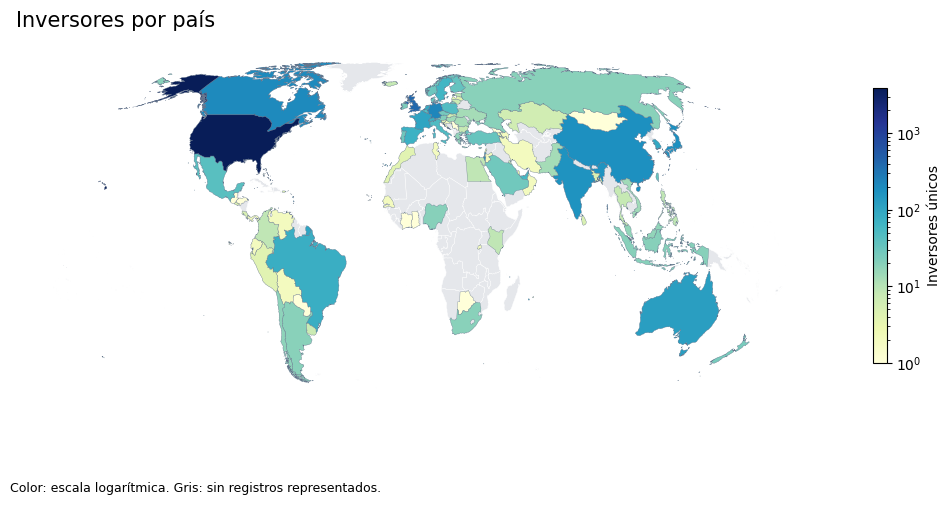

,pais,iso3,cantidad_inversores
220,United States of America,USA,3923
74,United Kingdom,GBR,396
54,Germany,DEU,218
36,Canada,CAN,201
107,Japan,JPN,179
39,People's Republic of China,CHN,178
96,India,IND,167
102,Israel,ISR,157
183,Singapore,SGP,146
13,Australia,AUS,123


In [ ]:
# MAPA: INVERSORES POR PAÍS
print(fuente_inversores_texto)
figura = dibujar_mapa_paises(
    mapa_datos, 'cantidad_inversores', 'Inversores por país', 'Inversores únicos', 'YlGnBu'
)
figura.text(0.12, 0.01, 'Color: escala logarítmica. Gris: sin registros representados.', fontsize=9)
figura.savefig(os.path.join(CARPETA_MAPAS, 'inversores_por_pais.png'), dpi=160, bbox_inches='tight')
plt.show()
plt.close(figura)
display(mapa_datos.loc[mapa_datos['cantidad_inversores'] > 0,
                       ['pais', 'iso3', 'cantidad_inversores']]
        .sort_values('cantidad_inversores', ascending=False).head(15).round(3))


Fuente: portfolios de startups — yigitmeteozcan/startups


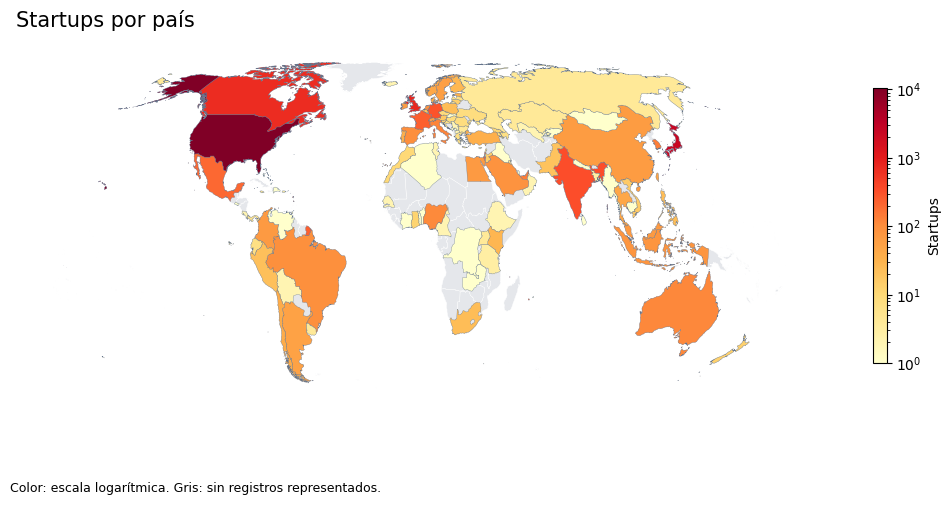

,pais,iso3,cantidad_startups
220,United States of America,USA,10633
107,Japan,JPN,2351
74,United Kingdom,GBR,792
36,Canada,CAN,697
96,India,IND,340
54,Germany,DEU,303
70,France,FRA,244
102,Israel,ISR,225
183,Singapore,SGP,218
134,Mexico,MEX,200


In [ ]:
# MAPA: STARTUPS POR PAÍS
print('Fuente: portfolios de startups — yigitmeteozcan/startups')
figura = dibujar_mapa_paises(
    mapa_datos, 'cantidad_startups', 'Startups por país', 'Startups', 'YlOrRd'
)
figura.text(0.12, 0.01, 'Color: escala logarítmica. Gris: sin registros representados.', fontsize=9)
figura.savefig(os.path.join(CARPETA_MAPAS, 'startups_por_pais.png'), dpi=160, bbox_inches='tight')
plt.show()
plt.close(figura)
display(mapa_datos.loc[mapa_datos['cantidad_startups'] > 0,
                       ['pais', 'iso3', 'cantidad_startups']]
        .sort_values('cantidad_startups', ascending=False).head(15).round(3))


Fuente: startups del proyecto + superficie de polígonos de Natural Earth


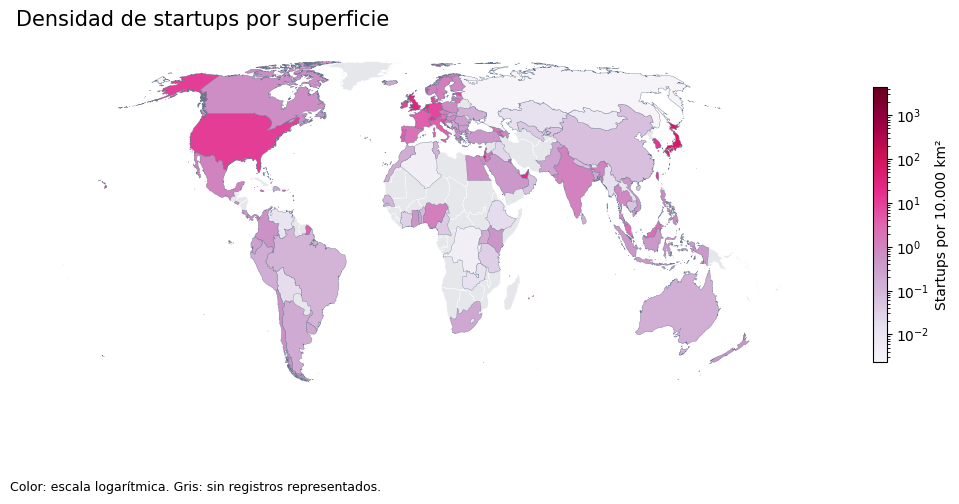

,pais,iso3,densidad_startups
183,Singapore,SGP,4515.418
51,Cayman Islands,CYM,499.322
225,British Virgin Islands,VGB,444.657
88,Hong Kong,HKG,389.744
76,Guernsey,GGY,207.417
28,Bermuda,BMU,151.654
22,Bahrain,BHR,129.518
102,Israel,ISR,102.119
107,Japan,JPN,63.494
74,United Kingdom,GBR,32.912


In [ ]:
# MAPA: DENSIDAD DE STARTUPS POR SUPERFICIE
print('Fuente: startups del proyecto + superficie de polígonos de Natural Earth')
figura = dibujar_mapa_paises(
    mapa_datos, 'densidad_startups', 'Densidad de startups por superficie', 'Startups por 10.000 km²', 'PuRd'
)
figura.text(0.12, 0.01, 'Color: escala logarítmica. Gris: sin registros representados.', fontsize=9)
figura.savefig(os.path.join(CARPETA_MAPAS, 'densidad_startups.png'), dpi=160, bbox_inches='tight')
plt.show()
plt.close(figura)
display(mapa_datos.loc[mapa_datos['densidad_startups'] > 0,
                       ['pais', 'iso3', 'densidad_startups']]
        .sort_values('densidad_startups', ascending=False).head(15).round(3))


In [ ]:
# 5. GUARDAR UNA TABLA POR PAÍS Y UNA IMAGEN CON LOS TRES MAPAS
tabla_paises_mapas = mapa_datos[
    ['pais', 'iso3', 'cantidad_inversores', 'cantidad_startups', 'area_km2', 'densidad_startups']
].copy().sort_values('cantidad_startups', ascending=False)
tabla_paises_mapas.to_csv(
    os.path.join(CARPETA_MAPAS, 'resumen_por_pais.csv'), index=False, encoding='utf-8-sig'
)
resumen_cobertura_mapas.to_csv(
    os.path.join(CARPETA_MAPAS, 'cobertura_datos.csv'), index=False, encoding='utf-8-sig'
)

figura_resumen, ejes = plt.subplots(3, 1, figsize=(13, 16))
for eje, columna, titulo, etiqueta, paleta in [
    (ejes[0], 'cantidad_inversores', 'Inversores por país', 'Inversores únicos', 'YlGnBu'),
    (ejes[1], 'cantidad_startups', 'Startups por país', 'Startups', 'YlOrRd'),
    (ejes[2], 'densidad_startups', 'Densidad de startups', 'Startups por 10.000 km²', 'PuRd'),
]:
    dibujar_mapa_paises(mapa_datos, columna, titulo, etiqueta, paleta, eje=eje)

figura_resumen.suptitle('Startup Intelligence · Distribución por país', fontsize=20, y=0.99)
figura_resumen.text(0.10, 0.025, fuente_inversores_texto + '\n'
                    'Startups: portfolios del proyecto. Geografía: Natural Earth.\n'
                    'Color: escala logarítmica. Gris: sin registros representados.', fontsize=10)
figura_resumen.subplots_adjust(top=0.95, bottom=0.09, hspace=0.15)
figura_resumen.savefig(os.path.join(CARPETA_MAPAS, 'resumen_tres_mapas.png'),
                       dpi=150, bbox_inches='tight')
plt.close(figura_resumen)
print('Mapas y tablas guardados en:', os.path.abspath(CARPETA_MAPAS))

# En Colab, para descargar la imagen con los tres mapas:
# from google.colab import files
# files.download(os.path.join(CARPETA_MAPAS, 'resumen_tres_mapas.png'))


Mapas y tablas guardados en: /content/mapas_startup_intelligence


### Fuentes y atribución

- Startups: [yigitmeteozcan/startups](https://github.com/yigitmeteozcan/startups).
- Fondos VC: [FundraisingFox — dataset abierto](https://github.com/fundraisingfox/data),
  licencia CC BY 4.0. Se usan `firm_type == 'vc'` y el país de sede `hq_country`.
- Opción histórica: [Crunchbase, octubre de 2013](https://github.com/dsagal/crunchbase-october-2013).
- Geografía: [Natural Earth, países 1:50 millones](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/50m-admin-0-countries-2/),
  archivo del repositorio `nvkelso/natural-earth-vector`.
- Código geográfico: [mapas con GeoPandas](https://geopandas.org/en/stable/docs/user_guide/mapping.html).

Se hicieron transformaciones para normalizar países, deduplicar inversores, agregar conteos
y calcular densidades por superficie. Los datos descargados pueden cambiar entre ejecuciones.

## 2. Preparar los mismos datos para la aplicación Flask

Convertimos el JSON al formato que usa el Radar: etiquetas y fundadores como texto,
enlaces de contacto y país normalizado. La geografía se reutiliza de los mapas anteriores.

In [ ]:
# Una sola base de startups para Explorar, Métricas, Mapas y Matching.
# startups_cruce conserva la depuración por nombre del notebook nuevo.
def texto_seguro(valor):
    return valor if isinstance(valor, str) else ''


filas_app = []
nombres_paises_app = dict(zip(mundo_mapas['iso3'], mundo_mapas['pais']))
for _, fila in startups_cruce.iterrows():
    extra = fila.get('extra', {})
    extra = extra if isinstance(extra, dict) else {}
    social = fila.get('social', {})
    social = social if isinstance(social, dict) else {}
    ubicacion = texto_seguro(fila.get('location', '')).split(';')[0]
    partes = [p.strip() for p in ubicacion.split(',')]
    tags = fila.get('tags', [])
    fundadores = fila.get('founders', [])
    nombres = []
    if isinstance(fundadores, list):
        for fundador in fundadores:
            nombre = fundador.get('name', '') if isinstance(fundador, dict) else fundador
            if isinstance(nombre, str) and nombre.strip():
                nombres.append(nombre.strip())
    registro = {c: texto_seguro(fila.get(c, '')) for c in
                ['name', 'description', 'website', 'source', 'program', 'region', 'subregion', 'logo']}
    registro.update({
        'city': texto_seguro(extra.get('city', '')) or (partes[0] if len(partes) > 1 else ''),
        'state': texto_seguro(extra.get('state_province', '')),
        'country': nombres_paises_app.get(pais_startup_mapa(fila), ''),
        'tags': '; '.join(str(t) for t in tags) if isinstance(tags, list) else texto_seguro(tags),
        'founders': '; '.join(nombres) if isinstance(fundadores, list) else texto_seguro(fundadores),
        'year': fila.get('year', ''),
        'isExit': fila.get('isExit', False), 'isUnicorn': fila.get('isUnicorn', False),
        'isBCorp': fila.get('isBCorp', False),
        'linkedin': texto_seguro(social.get('linkedin', '')),
        'twitter': texto_seguro(social.get('twitter', '')),
        'facebook': texto_seguro(social.get('facebook', '')),
        'crunchbase': texto_seguro(social.get('crunchbase', '')),
    })
    filas_app.append(registro)
df_original = pd.DataFrame(filas_app)
print('Registros que usará la web:', len(df_original))


Registros que usará la web: 20170


In [ ]:
mundo_original = paises_originales_mapa.copy()
mundo = mundo_mapas.rename(columns={'pais': 'nombre_mapa'}).copy()
CODIGO_POR_PAIS = {}
NOMBRE_POR_CODIGO = dict(zip(mundo['iso3'], mundo['nombre_mapa']))
for _, fila in mundo_original.iterrows():
    for columna in ['ADMIN', 'NAME_EN', 'NAME_LONG', 'NAME', 'ISO_A2_EH', 'ISO_A3_EH']:
        nombre = fila[columna]
        if isinstance(nombre, str) and nombre and nombre != '-99':
            CODIGO_POR_PAIS[nombre.casefold()] = fila['iso3']

# Variantes habituales en el CSV y en los diccionarios del proyecto.
CODIGO_POR_PAIS.update({
    'united states': 'USA', 'usa': 'USA', 'us': 'USA',
    'uk': 'GBR', 'england': 'GBR', 'south korea': 'KOR',
    'north korea': 'PRK', 'democratic peoples republic of korea': 'PRK',
    'czech republic': 'CZE', 'ivory coast': 'CIV', "cote d'ivoire": 'CIV',
    'côte d’ivoire': 'CIV', 'vietnam': 'VNM', 'viet nam': 'VNM',
    'türkiye': 'TUR', 'turkiye': 'TUR', 'belgië': 'BEL', 'kosovo': 'XKX',
    'uae': 'ARE', 'palestine': 'PSE',
})
print('Países y territorios disponibles en el mapa:', len(mundo))


Países y territorios disponibles en el mapa: 236


In [ ]:
# --- 3.1 Países y regiones -----------------------------------------------

# Diccionario: región -> lista de países que pertenecen a ella
PAISES_POR_REGION = {
    "Norteamérica": ["United States", "Canada"],
    "Latinoamérica": ["Mexico", "Brazil", "Argentina", "Chile", "Colombia", "Peru", "Uruguay",
                      "Ecuador", "Bolivia", "Paraguay", "Venezuela", "Panama", "Costa Rica",
                      "Guatemala", "Dominican Republic", "Puerto Rico", "Jamaica",
                      "Trinidad and Tobago", "Cayman Islands", "British Virgin Islands"],
    "Europa": ["United Kingdom", "Germany", "France", "Spain", "Italy", "Netherlands", "Sweden",
               "Switzerland", "Ireland", "Norway", "Denmark", "Finland", "Estonia", "Portugal",
               "Belgium", "Poland", "Lithuania", "Austria", "Slovenia", "Hungary", "Ukraine",
               "Romania", "Latvia", "Greece", "Croatia", "Bulgaria", "Iceland", "Czechia",
               "Luxembourg", "Cyprus", "Serbia", "Slovakia", "Malta", "Russia", "Georgia",
               "Armenia", "Azerbaijan", "Turkey", "North Macedonia"],
    "Medio Oriente y África": ["Israel", "United Arab Emirates", "Saudi Arabia", "Egypt", "Nigeria",
                               "Kenya", "South Africa", "Jordan", "Ghana", "Morocco", "Lebanon",
                               "Bahrain", "Kuwait", "Uganda", "Cameroon", "Tanzania", "Senegal",
                               "Ethiopia", "Oman", "Qatar", "Tunisia", "Algeria", "Rwanda", "Iraq",
                               "Ivory Coast", "Zambia", "Zimbabwe"],
    "Asia-Pacífico": ["Japan", "India", "Singapore", "South Korea", "China", "Indonesia", "Malaysia",
                      "Taiwan", "Thailand", "Hong Kong", "Australia", "New Zealand", "Pakistan",
                      "Philippines", "Vietnam", "Bangladesh", "Kazakhstan", "Sri Lanka", "Nepal"],
}

# Invertimos el diccionario para buscar rápido: país -> región
REGION_DE_PAIS = {}
for region, paises in PAISES_POR_REGION.items():
    for pais in paises:
        REGION_DE_PAIS[pais] = region

# Nombres alternativos que aparecen en el dataset
ALIAS_PAISES = {
    "usa": "United States", "us": "United States", "united states of america": "United States",
    "uk": "United Kingdom", "england": "United Kingdom", "czech republic": "Czechia",
    "uae": "United Arab Emirates", "korea": "South Korea",
    "türkiye": "Turkey", "turkiye": "Turkey", "viet nam": "Vietnam",
    "belgië": "Belgium", "cote d'ivoire": "Ivory Coast",
}

# Cuando no hay país, usamos la columna "region" original como pista
REGION_ORIGINAL_A_NUEVA = {
    "United States of America": "Norteamérica", "North America": "Norteamérica",
    "Latin America": "Latinoamérica", "Europe": "Europa", "EMEA": "Europa",
    "Asia": "Asia-Pacífico", "South Asia": "Asia-Pacífico", "Southeast Asia": "Asia-Pacífico",
    "North Asia": "Asia-Pacífico", "Oceania": "Asia-Pacífico",
    "Middle East & Africa": "Medio Oriente y África", "Middle East": "Medio Oriente y África",
    "Africa": "Medio Oriente y África",
}


def normalizar_pais(texto):
    """Recibe un país escrito de cualquier forma y devuelve el nombre estándar (o "" si no lo reconoce)."""
    if not isinstance(texto, str) or not texto.strip():
        return ""
    texto = texto.split(";")[0].strip()       # "USA; Remote" -> "USA"
    clave = texto.lower()
    if clave in ALIAS_PAISES:
        return ALIAS_PAISES[clave]
    for pais in REGION_DE_PAIS:                # comparamos sin importar mayúsculas
        if pais.lower() == clave:
            return pais
    codigo = CODIGO_POR_PAIS.get(clave.casefold())
    return NOMBRE_POR_CODIGO.get(codigo, "")


def obtener_pais(fila):
    """Busca el país en la columna 'country' y, si no está, en 'region'."""
    pais = normalizar_pais(fila["country"])
    if pais == "":
        pais = normalizar_pais(fila["region"])
    return pais


def obtener_region(fila):
    """Devuelve la región (continente) de una startup."""
    if fila["pais"] in REGION_DE_PAIS:
        return REGION_DE_PAIS[fila["pais"]]
    return REGION_ORIGINAL_A_NUEVA.get(fila["region"], "Sin dato")


# Prueba rápida de las funciones
print(normalizar_pais("USA; Remote"), "|", normalizar_pais("UNITED KINGDOM"), "|", normalizar_pais("Narnia") or "(vacío)")


United States | United Kingdom | (vacío)


In [ ]:
# --- 3.2 Sectores ---------------------------------------------------------
# Cada sector tiene una lista de palabras clave. Si alguna aparece en los tags
# de la startup, le asignamos ese sector (una startup puede tener varios).

PALABRAS_POR_SECTOR = {
    "IA": ["artificial intelligence", "machine learning", "ai", "generative ai", "computer vision", "nlp", "deep learning"],
    "Fintech": ["fintech", "finance", "banking", "payments", "lending", "wealth", "accounting", "credit", "financial"],
    "Salud": ["health", "healthcare", "medical", "medtech", "healthtech", "wellness", "mental health", "telehealth"],
    "Biotech": ["biotech", "genomics", "drug discovery", "therapeutics", "pharma", "diagnostics", "life sciences"],
    "SaaS B2B": ["saas", "b2b", "enterprise", "productivity", "sales", "crm", "operations", "b2b software"],
    "Dev tools e infra": ["developer tools", "devops", "infrastructure", "cloud", "api", "open source", "data engineering", "analytics", "cloudtech and devops"],
    "Ciberseguridad": ["security", "cybersecurity", "fraud", "identity", "privacy"],
    "Consumo": ["consumer", "social", "community", "dating", "creator economy", "kids", "pets"],
    "E-commerce y retail": ["e-commerce", "ecommerce", "retail", "marketplace", "brand & retail", "fashion", "cpg"],
    "Clima y energía": ["climate", "climate tech", "energy", "cleantech", "sustainability", "carbon", "solar", "battery"],
    "Movilidad": ["mobility", "automotive", "transportation", "aviation", "drones", "aerospace", "space", "mobility & physical ai"],
    "Hardware y robótica": ["hardware", "robotics", "manufacturing", "industrials", "internet of things", "iot", "deeptech", "hard tech", "semiconductors"],
    "Logística": ["logistics", "supply chain", "delivery", "fleet", "freight"],
    "Educación": ["edtech", "education", "e-learning"],
    "Real estate": ["proptech", "real estate", "construction", "housing"],
    "Insurtech": ["insurtech", "insurance"],
    "Food y agro": ["food", "agtech", "agriculture", "food and beverage", "restaurant tech"],
    "RR.HH.": ["hr", "hrtech", "human resources", "recruiting", "hr tech", "future of work"],
    "Marketing y medios": ["marketing", "advertising", "adtech", "media", "content", "entertainment", "music", "video"],
    "Gaming": ["gaming", "games", "esports"],
    "Cripto y web3": ["crypto", "blockchain", "web3", "defi", "crypto / web3"],
    "Legal y gobierno": ["legal", "legaltech", "regtech", "compliance", "govtech", "government", "defense"],
}


def separar_tags(texto):
    """'Fintech; SaaS' -> ['Fintech', 'SaaS']"""
    return [t.strip() for t in texto.split(";") if t.strip() != ""]


def obtener_sectores(tags):
    """Recibe la lista de tags y devuelve la lista de sectores que le corresponden."""
    tags_minuscula = [t.lower() for t in tags]
    sectores = []
    for sector, palabras in PALABRAS_POR_SECTOR.items():
        for tag in tags_minuscula:
            if tag in palabras or any(p in tag for p in palabras if len(p) > 4):
                sectores.append(sector)
                break
    return sectores


print(obtener_sectores(["Artificial intelligence and machine learning", "Fintech", "Payments"]))


['IA', 'Fintech']


In [ ]:
# --- 3.3 Armamos la tabla limpia -----------------------------------------

NOMBRES_ACELERADORAS = {
    "yc": "Y Combinator", "techstars": "Techstars", "plugandplay": "Plug and Play",
    "500": "500 Global", "antler": "Antler", "alchemist": "Alchemist", "ef": "Entrepreneur First",
}


def crear_id(nombre, fuente):
    """Crea un identificador único y legible, por ejemplo 'digitalocean-techstars'."""
    return re.sub(r"[^a-z0-9]+", "-", f"{nombre}-{fuente}".lower()).strip("-")


def limpiar_dataset(df):
    df = df.copy()
    df["id"] = [crear_id(n, s) for n, s in zip(df["name"], df["source"])]

    # Resolver colisiones de slug sin perder las empresas ya deduplicadas por nombre.
    duplicados = df['id'].duplicated(keep=False)
    df.loc[duplicados, 'id'] = (df.loc[duplicados, 'id'] + '_' +
                               df.loc[duplicados, 'name'].apply(normalizar_nombre))
    df = df.drop_duplicates(subset='id')
    df["aceleradora"] = df["source"].map(NOMBRES_ACELERADORAS).fillna(df["source"])
    df["pais"] = df.apply(obtener_pais, axis=1)
    df["region_limpia"] = df.apply(obtener_region, axis=1)
    df["lista_tags"] = df["tags"].apply(separar_tags)
    df["sectores"] = df["lista_tags"].apply(obtener_sectores)
    df["anio"] = pd.to_numeric(df["year"], errors="coerce").fillna(0).astype(int)
    for columna in ["isExit", "isUnicorn", "isBCorp"]:
        df[columna] = df[columna].astype(str).str.lower() == "true"
    df["lista_fundadores"] = df["founders"].apply(separar_tags)
    # Texto en minúsculas para el buscador (nombre + descripción + tags)
    df["texto_busqueda"] = (df["name"] + " " + df["description"] + " " + df["tags"]).str.lower()
    return df.set_index("id", drop=False)


startups = limpiar_dataset(df_original)

print("Startups limpias:", len(startups))
print("\nPor región:")
print(startups["region_limpia"].value_counts())

# Auditoría: los vacíos no se convierten en un país supuesto.
print("Sin país reconocido:", int((startups["pais"] == "").sum()))
print("Registros descartados por ID repetido:", len(df_original) - len(startups))
print("La web usa la misma base deduplicada por nombre que los mapas del notebook nuevo.")


Startups limpias: 20170

Por región:
region_limpia
Norteamérica              11330
Asia-Pacífico              3583
Europa                     2232
Sin dato                   1747
Medio Oriente y África      751
Latinoamérica               527
Name: count, dtype: int64
Sin país reconocido: 1736
Registros descartados por ID repetido: 0
La web usa la misma base deduplicada por nombre que los mapas del notebook nuevo.


In [ ]:
def filtrar_startups(df, filtros, pipeline=None):
    """Aplica los filtros de a uno. Cada filtro vacío se ignora."""
    resultado = df

    texto = filtros.get("q", "").strip().lower()
    if texto:
        resultado = resultado[resultado["texto_busqueda"].str.contains(texto, regex=False)]

    if filtros.get("sector"):
        resultado = resultado[resultado["sectores"].apply(lambda lista: filtros["sector"] in lista)]

    if filtros.get("region"):
        resultado = resultado[resultado["region_limpia"] == filtros["region"]]

    if filtros.get("pais"):
        resultado = resultado[resultado["pais"] == filtros["pais"]]

    if filtros.get("aceleradora"):
        resultado = resultado[resultado["aceleradora"] == filtros["aceleradora"]]

    if str(filtros.get("desde", "")).isdigit():
        resultado = resultado[resultado["anio"] >= int(filtros["desde"])]

    if str(filtros.get("hasta", "")).isdigit():
        resultado = resultado[(resultado["anio"] <= int(filtros["hasta"])) & (resultado["anio"] > 0)]

    if filtros.get("unicornio"):
        resultado = resultado[resultado["isUnicorn"]]
    if filtros.get("exit"):
        resultado = resultado[resultado["isExit"]]
    if filtros.get("bcorp"):
        resultado = resultado[resultado["isBCorp"]]
    if filtros.get("con_linkedin"):
        resultado = resultado[resultado["linkedin"] != ""]
    if filtros.get("con_fundadores"):
        resultado = resultado[resultado["founders"] != ""]

    if filtros.get("estado") and pipeline is not None:
        if filtros["estado"] == "sin_estado":
            resultado = resultado[~resultado["id"].isin(pipeline.keys())]
        else:
            ids = [i for i, datos in pipeline.items() if datos["estado"] == filtros["estado"]]
            resultado = resultado[resultado["id"].isin(ids)]

    return resultado


def ordenar_startups(df, criterio):
    if criterio == "nombre":
        return df.sort_values("name", key=lambda s: s.str.lower())
    if criterio == "antiguas":
        return df[df["anio"] > 0].sort_values("anio")
    # Por defecto: unicornios y exits primero, después las más nuevas
    return df.sort_values(["isUnicorn", "isExit", "anio"], ascending=False)


def calcular_metricas(df):
    """Devuelve un diccionario con los números principales del conjunto filtrado."""
    total = len(df)
    exits = int(df["isExit"].sum())
    con_anio = df[df["anio"] > 0]
    return {
        "total": total,
        "unicornios": int(df["isUnicorn"].sum()),
        "exits": exits,
        "tasa_exit": round(100 * exits / total, 1) if total > 0 else 0,
        "bcorps": int(df["isBCorp"].sum()),
        "paises": df.loc[df["pais"] != "", "pais"].nunique(),
        "anio_mediano": int(con_anio["anio"].median()) if len(con_anio) > 0 else "-",
    }


def contar_sectores(df, top=12):
    """Cuenta cuántas startups hay en cada sector (una startup puede sumar en varios)."""
    conteo = {}
    for lista in df["sectores"]:
        for sector in lista:
            conteo[sector] = conteo.get(sector, 0) + 1
    ordenado = sorted(conteo.items(), key=lambda par: par[1], reverse=True)
    return ordenado[:top]


def resumen_por_aceleradora(df):
    """Tabla con cantidad de startups, exits, unicornios y tasa de exit por aceleradora."""
    tabla = df.groupby("aceleradora").agg(
        startups=("id", "count"), exits=("isExit", "sum"), unicornios=("isUnicorn", "sum"))
    tabla["tasa_exit"] = (100 * tabla["exits"] / tabla["startups"]).round(1)
    return tabla.sort_values("startups", ascending=False).reset_index()


# Probamos: startups de IA en Latinoamérica
prueba = filtrar_startups(startups, {"sector": "IA", "region": "Latinoamérica"})
print("IA en Latinoamérica:", calcular_metricas(prueba))
print(contar_sectores(startups, top=5))
resumen_por_aceleradora(startups)


IA en Latinoamérica: {'total': 50, 'unicornios': 0, 'exits': 1, 'tasa_exit': 2.0, 'bcorps': 0, 'paises': 12, 'anio_mediano': 2022}
[('IA', 3870), ('Fintech', 2862), ('SaaS B2B', 2829), ('Salud', 2586), ('Hardware y robótica', 2050)]


,aceleradora,startups,exits,unicornios,tasa_exit
0,Y Combinator,6175,841,41,13.6
1,Techstars,5193,646,26,12.4
2,Plug and Play,4760,442,31,9.3
3,500 Global,2055,600,8,29.2
4,Antler,1028,0,0,0.0
5,Entrepreneur First,482,2,0,0.4
6,Alchemist,477,70,0,14.7


## 3. Pipeline, mensajes y gráficos de la aplicación anterior

Los estados y notas se guardan en `pipeline_startups.json`. Para conservarlos entre sesiones
de Colab, configurá la ruta de Google Drive indicada en la celda siguiente.

In [ ]:
# --- Opcional: guardar en Google Drive para no perder el pipeline ---
# from google.colab import drive
# drive.mount("/content/drive")
# ARCHIVO_PIPELINE = "/content/drive/MyDrive/pipeline_startups.json"

ARCHIVO_PIPELINE = "pipeline_startups.json"

ESTADOS = {
    "shortlist":  "⭐ Shortlist",
    "contactada": "✉️ Contactada",
    "respondio":  "💬 Respondió",
    "reunion":    "📅 Reunión",
    "descartada": "✖️ Descartada",
}


def cargar_pipeline():
    if os.path.exists(ARCHIVO_PIPELINE):
        with open(ARCHIVO_PIPELINE, "r", encoding="utf-8") as archivo:
            return json.load(archivo)
    return {}


def guardar_pipeline(pipeline):
    with open(ARCHIVO_PIPELINE, "w", encoding="utf-8") as archivo:
        json.dump(pipeline, archivo, ensure_ascii=False, indent=2)


def actualizar_startup(pipeline, id_startup, estado, notas=None):
    """Cambia el estado de una startup. Si el estado es "" la saca del pipeline."""
    if estado == "":
        pipeline.pop(id_startup, None)
    else:
        datos = pipeline.get(id_startup, {"notas": ""})
        datos["estado"] = estado
        if notas is not None:
            datos["notas"] = notas
        datos["actualizado"] = datetime.now().strftime("%Y-%m-%d %H:%M")
        pipeline[id_startup] = datos
    guardar_pipeline(pipeline)


pipeline = cargar_pipeline()
print("Startups en el pipeline:", len(pipeline))


Startups en el pipeline: 0


In [ ]:
MI_NOMBRE = "Tu nombre"
MI_PROPUESTA = "explorar una posible colaboración"


def generar_mensaje(startup, idioma="es"):
    fundadores = startup["lista_fundadores"]
    saludo_nombre = fundadores[0].split()[0] if fundadores else None
    if idioma == "en":
        saludo = f"Hi {saludo_nombre}," if saludo_nombre else f"Hi {startup['name']} team,"
        return (f"{saludo}\n\n"
                f"I came across {startup['name']} through {startup['aceleradora']} "
                f"({startup['program']}) and really liked what you're building: {startup['description']}\n\n"
                f"I'd love to set up a short call to {MI_PROPUESTA}. Would you have 20 minutes next week?\n\n"
                f"Best,\n{MI_NOMBRE}")
    saludo = f"Hola {saludo_nombre}," if saludo_nombre else f"Hola equipo de {startup['name']},"
    return (f"{saludo}\n\n"
            f"Conocí {startup['name']} a través de {startup['aceleradora']} "
            f"({startup['program']}) y me interesó mucho lo que están haciendo: {startup['description']}\n\n"
            f"Me gustaría coordinar una llamada breve para {MI_PROPUESTA}. ¿Tendrían 20 minutos la semana próxima?\n\n"
            f"Saludos,\n{MI_NOMBRE}")


print(generar_mensaje(startups.loc["digitalocean-techstars"]))


Hola equipo de DigitalOcean,

Conocí DigitalOcean a través de Techstars (Techstars Boulder Accelerator) y me interesó mucho lo que están haciendo: Simple, scalable cloud computing solutions built for startups and small-to-midsize businesses.

Me gustaría coordinar una llamada breve para explorar una posible colaboración. ¿Tendrían 20 minutos la semana próxima?

Saludos,
Tu nombre


In [ ]:
matplotlib.use("Agg")

COLOR_PRINCIPAL = "#2b59c3"


def figura_a_base64(figura):
    buffer = io.BytesIO()
    figura.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(figura)
    return base64.b64encode(buffer.getvalue()).decode("ascii")


def grafico_por_anio(df):
    conteo = df[(df["anio"] >= 2005) & (df["anio"] <= datetime.now().year)]["anio"].value_counts().sort_index()
    figura, eje = plt.subplots(figsize=(8, 3.2))
    eje.bar(conteo.index, conteo.values, color=COLOR_PRINCIPAL)
    eje.set_title("Startups por año de ingreso a la aceleradora", loc="left")
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="y", alpha=0.3)
    return figura_a_base64(figura)


def grafico_barras_horizontales(pares, titulo):
    """pares = [(etiqueta, valor), ...]"""
    etiquetas = [p[0] for p in pares][::-1]
    valores = [p[1] for p in pares][::-1]
    figura, eje = plt.subplots(figsize=(5, 0.32 * len(pares) + 0.8))
    eje.barh(etiquetas, valores, color=COLOR_PRINCIPAL)
    for i, v in enumerate(valores):
        eje.text(v, i, f" {v:,}".replace(",", "."), va="center", fontsize=9)
    eje.set_title(titulo, loc="left")
    eje.spines[["top", "right"]].set_visible(False)
    eje.set_xticks([])
    return figura_a_base64(figura)


def grafico_sectores(df):
    return grafico_barras_horizontales(contar_sectores(df, top=12), "Sectores más frecuentes")


def grafico_paises(df):
    conteo = df[df["pais"] != ""]["pais"].value_counts().head(10)
    return grafico_barras_horizontales(list(conteo.items()), "Top 10 países")


def resumen_geografico(df):
    """Une los conteos filtrados con los polígonos; no multiplica registros."""
    codigos = df['pais'].str.casefold().map(CODIGO_POR_PAIS)
    conteo = codigos.value_counts().rename_axis('iso3').reset_index(name='cantidad')
    tabla = mundo.merge(conteo, on='iso3', how='left', validate='one_to_one')
    tabla['cantidad'] = tabla['cantidad'].fillna(0).astype(int)
    tabla['densidad'] = tabla['cantidad'] / tabla['area_km2'] * 10_000
    cobertura = {
        'total': len(df),
        'mapeadas': int(codigos.isin(mundo['iso3']).sum()),
        'sin_pais': int((df['pais'] == '').sum()),
        'sin_poligono': int(((df['pais'] != '') & ~codigos.isin(mundo['iso3'])).sum()),
    }
    return tabla, cobertura


def grafico_mapa(df, medida='cantidad'):
    tabla, cobertura = resumen_geografico(df)
    figura, eje = plt.subplots(figsize=(12, 4.8))
    proyectada = tabla.to_crs('EPSG:8857')
    proyectada.plot(ax=eje, color='#e6e9ee', edgecolor='#ffffff', linewidth=0.25)
    positivas = proyectada[proyectada['cantidad'] > 0]
    if len(positivas):
        # El color usa escala logarítmica: hay países con 1 registro y otros con miles.
        # La leyenda sigue expresando cantidades/densidades en sus unidades originales.
        minimo = float(positivas[medida].min())
        maximo = float(positivas[medida].max())
        escala = matplotlib.colors.LogNorm(vmin=minimo, vmax=maximo) if maximo > minimo else None
        positivas.plot(column=medida, ax=eje, cmap='YlOrRd', legend=True,
                       norm=escala,
                       edgecolor='#64748b', linewidth=0.25,
                       legend_kwds={'label': 'Registros' if medida == 'cantidad'
                                    else 'Registros por 10.000 km²', 'shrink': 0.65})
    else:
        eje.text(0.5, 0.5, 'No hay registros con país mapeable para estos filtros.',
                 transform=eje.transAxes, ha='center', va='center')
    titulo = 'Cantidad de startups por país' if medida == 'cantidad' else 'Densidad de startups por superficie'
    eje.set_title(titulo, loc='left', fontsize=15, pad=14)
    eje.set_axis_off()
    figura.text(0.12, 0.01, 'Color: escala logarítmica. Gris: sin registros. Fuentes: portfolios + Natural Earth.',
                 fontsize=9, color='#526176')
    return figura_a_base64(figura), tabla, cobertura


In [ ]:
# Los inversores se cargan automáticamente desde las fuentes del notebook nuevo.
# Conservamos también la posibilidad de cargar un CSV propio.
COL_NOMBRE_INVERSOR = 'name'
COL_PAIS_INVERSOR = 'country'
COL_WEB_INVERSOR = 'website'
COL_WEB_STARTUP = 'startup_website'
SEPARADOR_INVERSORES = ','


def codigo_de_pais(valor):
    # Misma normalización para todos los listados de inversores.
    return normalizar_pais_mapa(valor)


def preparar_inversores(tabla):
    faltan = [c for c in [COL_NOMBRE_INVERSOR, COL_PAIS_INVERSOR] if c not in tabla]
    if faltan:
        raise ValueError('Faltan columnas: ' + ', '.join(faltan))
    resultado = pd.DataFrame(index=tabla.index)
    resultado['name'] = tabla[COL_NOMBRE_INVERSOR].fillna('').astype(str).str.strip()
    resultado['iso3'] = tabla[COL_PAIS_INVERSOR].apply(codigo_de_pais)
    resultado['pais'] = resultado['iso3'].map(NOMBRE_POR_CODIGO).fillna('')
    resultado['url'] = tabla[COL_WEB_INVERSOR].fillna('') if COL_WEB_INVERSOR in tabla else ''
    resultado['sectors'] = ''
    resultado['stages'] = ''
    resultado['slug'] = ''
    resultado['id_inversor'] = resultado['name'].apply(normalizar_nombre) + '|' + resultado['url']
    return resultado[resultado['name'] != ''].drop_duplicates('id_inversor').reset_index(drop=True)


def preparar_fuentes_web():
    fondos_web = fondos_vc.copy()
    fondos_web['iso3'] = fondos_web['hq_country'].apply(codigo_de_pais)
    fondos_web['pais'] = fondos_web['iso3'].map(NOMBRE_POR_CODIGO).fillna('')
    fondos_web['id_inversor'] = fondos_web['slug'].fillna('')
    sin_id = fondos_web['id_inversor'] == ''
    fondos_web.loc[sin_id, 'id_inversor'] = fondos_web.loc[sin_id, 'name'].apply(normalizar_nombre)
    fondos_web['url'] = fondos_web['fundraisingfox_url'].fillna('')
    fondos_web = fondos_web.drop_duplicates('id_inversor').fillna('')

    historicos = vc.copy()
    historicos['iso3'] = historicos['investor_country_code'].apply(codigo_de_pais)
    historicos['id_inversor'] = historicos['investor_permalink'].fillna('')
    sin_id = historicos['id_inversor'] == ''
    historicos.loc[sin_id, 'id_inversor'] = historicos.loc[sin_id, 'investor_name'].apply(normalizar_nombre)
    historicos['con_pais'] = historicos['iso3'] != ''
    historicos = historicos[historicos['id_inversor'] != ''].sort_values(
        'con_pais', ascending=False, kind='stable').drop_duplicates('id_inversor').copy()
    historicos['name'] = historicos['investor_name'].fillna('')
    historicos['pais'] = historicos['iso3'].map(NOMBRE_POR_CODIGO).fillna('')
    historicos['url'] = ''
    historicos['sectors'] = ''
    historicos['stages'] = ''
    historicos['slug'] = ''
    columnas = ['id_inversor', 'name', 'iso3', 'pais', 'url', 'sectors', 'stages', 'slug']
    return {'fondos': fondos_web[columnas].copy(), 'crunchbase': historicos[columnas].copy(),
            'csv': pd.DataFrame(columns=columnas)}


FUENTES_WEB = preparar_fuentes_web()
NOMBRES_FUENTES_WEB = {
    'fondos': 'FundraisingFox · fondos VC por país de sede',
    'crunchbase': 'Crunchbase · inversores del snapshot de octubre de 2013',
    'csv': 'CSV propio cargado en esta sesión',
}
startups['familias_match'] = startups['lista_tags'].apply(clasificar_sectores)


def seleccionar_inversores(fuente='fondos', pais='', consulta=''):
    tabla = FUENTES_WEB.get(fuente, FUENTES_WEB['fondos'])
    if pais:
        tabla = tabla[tabla['iso3'] == pais]
    if consulta:
        tabla = tabla[tabla['name'].str.contains(consulta, case=False, regex=False, na=False)]
    return tabla.copy()


def datos_mapa_web(filtradas, inversores_seleccionados):
    tabla, cobertura = resumen_geografico(filtradas)
    conteo = inversores_seleccionados[inversores_seleccionados['iso3'] != ''].groupby('iso3').size()
    conteo = conteo.rename('inversores').reset_index()
    tabla = tabla.merge(conteo, on='iso3', how='left', validate='one_to_one')
    tabla['inversores'] = tabla['inversores'].fillna(0).astype(int)
    cobertura['total_inversores'] = len(inversores_seleccionados)
    cobertura['inversores_mapeados'] = int(inversores_seleccionados['iso3'].isin(mundo['iso3']).sum())
    return tabla, cobertura


def imagen_mapa_web(tabla, medida):
    configuracion = {
        'cantidad': ('Startups por país', 'Startups', 'YlOrRd'),
        'densidad': ('Densidad de startups', 'Startups por 10.000 km²', 'PuRd'),
        'inversores': ('Inversores por país', 'Inversores únicos', 'YlGnBu'),
    }
    titulo, etiqueta, colores = configuracion[medida]
    figura, eje = plt.subplots(figsize=(12, 4.8))
    proyectada = tabla.to_crs('EPSG:8857')
    proyectada.plot(ax=eje, color='#e5e7eb', edgecolor='white', linewidth=0.3)
    positivas = proyectada[proyectada[medida] > 0]
    if len(positivas):
        minimo, maximo = float(positivas[medida].min()), float(positivas[medida].max())
        escala = matplotlib.colors.LogNorm(vmin=minimo, vmax=maximo) if maximo > minimo else None
        positivas.plot(column=medida, cmap=colores, norm=escala, ax=eje, legend=True,
                       edgecolor='#64748b', linewidth=0.25,
                       legend_kwds={'label': etiqueta, 'shrink': 0.65})
    else:
        eje.text(0.5, 0.5, 'No hay registros mapeables en esta selección.',
                 transform=eje.transAxes, ha='center', va='center')
    eje.set_title(titulo, loc='left', pad=14)
    eje.set_axis_off()
    figura.text(0.12, 0.01, 'Color: escala logarítmica · Gris: sin registros · Geografía: Natural Earth', fontsize=9)
    return figura_a_base64(figura)


def fondos_para_empresa(empresa, etapa=''):
    familias = empresa['familias_match']
    candidatos = vc_match.copy()
    if etapa:
        buscada = normalizar(etapa)
        candidatos = candidatos[candidatos['etapas_lista'].apply(lambda valores: buscada in valores)]
    candidatos['coincidencias'] = candidatos['familias'].apply(lambda f: len(f.intersection(familias)))
    candidatos = candidatos[candidatos['coincidencias'] > 0].copy()
    candidatos['compatibilidad_pct'] = (100 * candidatos['coincidencias'] / len(familias)).round(1) if familias else 0
    candidatos['sectores_comunes'] = candidatos['familias'].apply(lambda f: ', '.join(sorted(f.intersection(familias))))
    return candidatos.sort_values(['coincidencias', 'portfolio_count'], ascending=False, na_position='last')


def empresas_para_fondo(fondo):
    familias = fondo['familias']
    candidatos = startups.copy()
    candidatos['coincidencias'] = candidatos['familias_match'].apply(lambda f: len(f.intersection(familias)))
    candidatos = candidatos[candidatos['coincidencias'] > 0].copy()
    candidatos['sectores_comunes'] = candidatos['familias_match'].apply(lambda f: ', '.join(sorted(f.intersection(familias))))
    return candidatos.sort_values('coincidencias', ascending=False)


print('Fuentes de inversores conectadas:', {k: len(v) for k, v in FUENTES_WEB.items()})


Fuentes de inversores conectadas: {'fondos': 8481, 'crunchbase': 10552, 'csv': 0}


## 4. Páginas y rutas de Flask

La misma aplicación contiene filtros, fichas, métricas, mapas, directorio de inversores,
matching en ambos sentidos y pipeline. Las tablas por país se descargan desde **Mapas**.

In [ ]:
PLANTILLA_BASE = """
<!doctype html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Radar de Startups</title>
<style>
  :root { --fondo:#f4f6fa; --tarjeta:#fff; --texto:#1b2333; --suave:#667085; --borde:#e2e6ee;
          --azul:#2b59c3; --dorado:#b7791f; --verde:#2f855a; --rojo:#c53030; }
  * { box-sizing: border-box; }
  body { margin:0; font-family: system-ui, -apple-system, "Segoe UI", sans-serif; background:var(--fondo); color:var(--texto); font-size:14px; }
  a { color: var(--azul); text-decoration: none; }
  a:hover { text-decoration: underline; }
  header { background:#16213a; color:#fff; padding:12px 24px; display:flex; gap:24px; align-items:center; flex-wrap:wrap; }
  header .logo { font-weight:800; font-size:18px; }
  header nav a { color:#c8d3ee; margin-right:16px; font-weight:600; }
  header nav a.activo { color:#fff; border-bottom:2px solid #fff; padding-bottom:2px; }
  main { padding:20px 24px; max-width:1400px; margin:0 auto; }
  .tarjeta { background:var(--tarjeta); border:1px solid var(--borde); border-radius:10px; padding:16px; }
  .kpis { display:grid; grid-template-columns:repeat(auto-fit, minmax(130px,1fr)); gap:12px; margin-bottom:16px; }
  .kpi .valor { font-size:24px; font-weight:800; font-variant-numeric:tabular-nums; }
  .kpi .etiqueta { color:var(--suave); font-size:12px; text-transform:uppercase; letter-spacing:.04em; }
  .layout { display:grid; grid-template-columns:260px 1fr; gap:16px; align-items:start; }
  @media (max-width: 800px) { .layout { grid-template-columns:1fr; } }
  form.filtros label { display:block; font-size:12px; font-weight:600; color:var(--suave); margin:10px 0 4px; }
  form.filtros input[type=text], form.filtros input[type=number], form.filtros select { width:100%; padding:7px; border:1px solid var(--borde); border-radius:6px; font-size:14px; }
  form.filtros .check { display:flex; gap:6px; align-items:center; margin:6px 0; font-size:13px; color:var(--texto); font-weight:400; }
  .fila-2 { display:flex; gap:8px; }
  button, .boton { background:var(--azul); color:#fff; border:none; border-radius:6px; padding:8px 14px; font-weight:600; cursor:pointer; font-size:13px; display:inline-block; white-space:nowrap; }
  .boton.secundario, button.secundario { background:#e8edf8; color:var(--azul); }
  table { width:100%; border-collapse:collapse; }
  th { text-align:left; font-size:12px; color:var(--suave); text-transform:uppercase; padding:8px; border-bottom:1px solid var(--borde); }
  td { padding:9px 8px; border-bottom:1px solid var(--borde); vertical-align:top; }
  tr:hover td { background:#f8faff; }
  .desc { color:var(--suave); font-size:13px; max-width:520px; }
  .chip { display:inline-block; background:#eef2fb; color:#34446b; border-radius:999px; padding:2px 8px; font-size:12px; margin:2px 2px 0 0; }
  .chip.unicornio { background:#fdf3e1; color:var(--dorado); font-weight:700; }
  .chip.exit { background:#e6f4ec; color:var(--verde); font-weight:700; }
  .chip.estado { background:#16213a; color:#fff; }
  .paginacion { display:flex; gap:8px; align-items:center; justify-content:space-between; margin-top:12px; flex-wrap:wrap; }
  .scroll { overflow-x:auto; }
  .detalle { display:grid; grid-template-columns:2fr 1fr; gap:16px; }
  @media (max-width: 800px) { .detalle { grid-template-columns:1fr; } }
  textarea { width:100%; border:1px solid var(--borde); border-radius:6px; padding:8px; font-family:inherit; font-size:13px; }
  .columnas { display:grid; grid-template-columns:repeat(auto-fit, minmax(240px,1fr)); gap:12px; }
  .graficos img { max-width:100%; }
  h1 { margin:0 0 4px; font-size:24px; } h2 { font-size:16px; margin:0 0 10px; }
  .muted { color:var(--suave); }
  .aviso { background:#e6f4ec; color:var(--verde); padding:10px 14px; border-radius:8px; margin-bottom:12px; font-weight:600; }
</style>
</head>
<body>
<header>
  <span class="logo">📡 Radar de Startups</span>
  <nav>
    <a href="{{ url_for('explorar') }}" class="{{ 'activo' if pagina=='explorar' }}">Explorar</a>
    <a href="{{ url_for('metricas', **request.args) }}" class="{{ 'activo' if pagina=='metricas' }}">Métricas</a>
    <a href="{{ url_for('ver_mapa', **request.args) }}" class="{{ 'activo' if pagina=='mapa' }}">Mapa</a>
    <a href="{{ url_for('ver_inversores', **request.args) }}" class="{{ 'activo' if pagina=='inversores' }}">Inversores</a>
    <a href="{{ url_for('ver_pipeline') }}" class="{{ 'activo' if pagina=='pipeline' }}">Mi pipeline ({{ cantidad_pipeline }})</a>
  </nav>
</header>
<main>
{% block contenido %}{% endblock %}
</main>
</body>
</html>
"""

# Formulario de filtros: lo usan Explorar y Métricas
PLANTILLA_FILTROS = """
<form class="filtros tarjeta" method="get" action="{{ accion }}">
  {% if pagina=="mapa" %}<input type="hidden" name="medida" value="{{ medida }}">{% endif %}
  <label for="q">Buscar</label>
  <input type="text" id="q" name="q" value="{{ f.q or '' }}" placeholder="nombre, producto, tag…">

  <label for="sector">Sector</label>
  <select id="sector" name="sector"><option value="">Todos</option>
    {% for s in opciones.sectores %}<option {{ 'selected' if f.sector==s }}>{{ s }}</option>{% endfor %}
  </select>

  <label for="region">Región</label>
  <select id="region" name="region"><option value="">Todas</option>
    {% for r in opciones.regiones %}<option {{ 'selected' if f.region==r }}>{{ r }}</option>{% endfor %}
  </select>

  <label for="pais">País</label>
  <select id="pais" name="pais"><option value="">Todos</option>
    {% for p in opciones.paises %}<option {{ 'selected' if f.pais==p }}>{{ p }}</option>{% endfor %}
  </select>

  <label for="aceleradora">Aceleradora</label>
  <select id="aceleradora" name="aceleradora"><option value="">Todas</option>
    {% for a in opciones.aceleradoras %}<option {{ 'selected' if f.aceleradora==a }}>{{ a }}</option>{% endfor %}
  </select>

  <label>Año de ingreso</label>
  <div class="fila-2">
    <input type="number" name="desde" value="{{ f.desde or '' }}" placeholder="desde" min="2005" max="2030">
    <input type="number" name="hasta" value="{{ f.hasta or '' }}" placeholder="hasta" min="2005" max="2030">
  </div>

  <label>Características</label>
  <span class="check"><input type="checkbox" id="unicornio" name="unicornio" value="1" {{ 'checked' if f.unicornio }}><label for="unicornio" style="margin:0">🦄 Unicornio (+US$1.000M)</label></span>
  <span class="check"><input type="checkbox" id="exit" name="exit" value="1" {{ 'checked' if f.exit }}><label for="exit" style="margin:0">💰 Tuvo exit</label></span>
  <span class="check"><input type="checkbox" id="bcorp" name="bcorp" value="1" {{ 'checked' if f.bcorp }}><label for="bcorp" style="margin:0">🌱 Empresa B</label></span>
  <span class="check"><input type="checkbox" id="con_linkedin" name="con_linkedin" value="1" {{ 'checked' if f.con_linkedin }}><label for="con_linkedin" style="margin:0">Tiene LinkedIn</label></span>
  <span class="check"><input type="checkbox" id="con_fundadores" name="con_fundadores" value="1" {{ 'checked' if f.con_fundadores }}><label for="con_fundadores" style="margin:0">Fundadores conocidos</label></span>

  <label for="estado">Estado en mi pipeline</label>
  <select id="estado" name="estado"><option value="">Cualquiera</option>
    <option value="sin_estado" {{ 'selected' if f.estado=='sin_estado' }}>Sin estado</option>
    {% for clave, nombre in estados.items() %}<option value="{{ clave }}" {{ 'selected' if f.estado==clave }}>{{ nombre }}</option>{% endfor %}
  </select>

  <label for="orden">Ordenar por</label>
  <select id="orden" name="orden">
    <option value="destacadas">Destacadas primero</option>
    <option value="nombre" {{ 'selected' if f.orden=='nombre' }}>Nombre (A-Z)</option>
    <option value="antiguas" {{ 'selected' if f.orden=='antiguas' }}>Más antiguas</option>
  </select>

  <div class="fila-2" style="margin-top:14px">
    <button type="submit">Aplicar</button>
    <a class="boton secundario" href="{{ accion }}">Limpiar</a>
  </div>
</form>
"""

PLANTILLA_KPIS = """
<div class="kpis">
  <div class="tarjeta kpi"><div class="valor">{{ "{:,}".format(m.total).replace(",", ".") }}</div><div class="etiqueta">Startups</div></div>
  <div class="tarjeta kpi"><div class="valor">{{ m.unicornios }}</div><div class="etiqueta">🦄 Unicornios</div></div>
  <div class="tarjeta kpi"><div class="valor">{{ m.exits }}</div><div class="etiqueta">💰 Exits</div></div>
  <div class="tarjeta kpi"><div class="valor">{{ m.tasa_exit }}%</div><div class="etiqueta">Tasa de exit</div></div>
  <div class="tarjeta kpi"><div class="valor">{{ m.paises }}</div><div class="etiqueta">Países</div></div>
  <div class="tarjeta kpi"><div class="valor">{{ m.anio_mediano }}</div><div class="etiqueta">Año mediano</div></div>
</div>
"""

PLANTILLA_EXPLORAR = """
{% extends "base.html" %}
{% block contenido %}
<div class="layout">
  {% with accion=url_for('explorar') %}{% include "filtros.html" %}{% endwith %}
  <section>
    {% include "kpis.html" %}
    <div class="tarjeta scroll">
      <table>
        <tr><th>Startup</th><th>Sectores</th><th>Ubicación</th><th>Aceleradora</th><th>Pipeline</th></tr>
        {% for s in filas %}
        <tr>
          <td>
            <a href="{{ url_for('detalle', id_startup=s.id) }}"><b>{{ s.name }}</b></a>
            {% if s.isUnicorn %}<span class="chip unicornio">🦄 Unicornio</span>{% endif %}
            {% if s.isExit %}<span class="chip exit">Exit</span>{% endif %}
            <div class="desc">{{ s.description[:160] }}{{ '…' if s.description|length > 160 }}</div>
          </td>
          <td>{% for sec in s.sectores[:3] %}<span class="chip">{{ sec }}</span>{% endfor %}</td>
          <td>{{ s.pais or '—' }}<div class="muted">{{ s.city }}</div></td>
          <td>{{ s.aceleradora }}<div class="muted">{{ s.anio if s.anio else '' }}</div></td>
          <td>
            {% if s.id in pipeline %}
              <span class="chip estado">{{ estados[pipeline[s.id].estado] }}</span>
            {% else %}
              <form method="post" action="{{ url_for('cambiar_estado', id_startup=s.id) }}">
                <input type="hidden" name="estado" value="shortlist">
                <input type="hidden" name="volver" value="{{ request.full_path }}">
                <button class="secundario" type="submit">+ Shortlist</button>
              </form>
            {% endif %}
          </td>
        </tr>
        {% else %}
        <tr><td colspan="5" class="muted">No hay startups con esos filtros. Probá sacando alguno.</td></tr>
        {% endfor %}
      </table>
      <div class="paginacion">
        <span class="muted">Mostrando {{ desde_n }}–{{ hasta_n }} de {{ m.total }}</span>
        <span>
          {% if pag > 1 %}<a class="boton secundario" href="{{ url_pagina(pag-1) }}">← Anterior</a>{% endif %}
          {% if hasta_n < m.total %}<a class="boton secundario" href="{{ url_pagina(pag+1) }}">Siguiente →</a>{% endif %}
        </span>
      </div>
    </div>
  </section>
</div>
{% endblock %}
"""

PLANTILLA_DETALLE = """
{% extends "base.html" %}
{% block contenido %}
<p><a href="javascript:history.back()">← Volver</a></p>
{% if guardado %}<div class="aviso">Cambios guardados ✔</div>{% endif %}
<div class="detalle">
  <section class="tarjeta">
    <h1>{{ s.name }}</h1>
    <p class="muted">{{ s.program }} · {{ s.city ~ ', ' if s.city }}{{ s.pais or 'País sin dato' }} · {{ s.region_limpia }}</p>
    <p>{% if s.isUnicorn %}<span class="chip unicornio">🦄 Unicornio</span>{% endif %}
       {% if s.isExit %}<span class="chip exit">💰 Exit</span>{% endif %}
       {% if s.isBCorp %}<span class="chip">🌱 Empresa B</span>{% endif %}
       {% for sec in s.sectores %}<span class="chip">{{ sec }}</span>{% endfor %}</p>
    <p style="font-size:15px">{{ s.description or 'Sin descripción.' }}</p>
    <p class="muted">Tags originales: {{ s.tags or '—' }}</p>

    <h2 style="margin-top:20px">Contacto</h2>
    <ul>
      {% if s.website %}<li>Sitio web: <a href="{{ s.website }}" target="_blank">{{ s.website }}</a></li>{% endif %}
      {% if s.linkedin %}<li>LinkedIn: <a href="{{ s.linkedin }}" target="_blank">{{ s.linkedin }}</a></li>
      {% else %}<li><a href="https://www.linkedin.com/search/results/companies/?keywords={{ s.name|urlencode }}" target="_blank">Buscar la empresa en LinkedIn</a></li>{% endif %}
      {% if s.twitter %}<li>X / Twitter: <a href="{{ s.twitter }}" target="_blank">{{ s.twitter }}</a></li>{% endif %}
      {% if s.crunchbase %}<li>Crunchbase: <a href="{{ s.crunchbase }}" target="_blank">{{ s.crunchbase }}</a></li>{% endif %}
      <li><a href="{{ busqueda_email }}" target="_blank">Buscar email de contacto en Google</a> <span class="muted">(el dataset no trae emails)</span></li>
    </ul>

    <h2 style="margin-top:20px">Fundadores</h2>
    {% if s.lista_fundadores %}
      <ul>{% for nombre in s.lista_fundadores %}
        <li>{{ nombre }} — <a href="https://www.linkedin.com/search/results/people/?keywords={{ (nombre ~ ' ' ~ s.name)|urlencode }}" target="_blank">buscar en LinkedIn</a></li>
      {% endfor %}</ul>
    {% else %}<p class="muted">El dataset no tiene los fundadores de esta startup.</p>{% endif %}

    <h2 style="margin-top:20px">Mensaje sugerido</h2>
    <p><a href="?idioma=es">Español</a> · <a href="?idioma=en">English</a></p>
    <textarea rows="11" id="mensaje">{{ mensaje }}</textarea>
    <p class="muted">Copialo y pegalo en LinkedIn o en un email. Cambiá MI_NOMBRE y MI_PROPUESTA en la parte 6 del notebook.</p>
  </section>

  <aside class="tarjeta">
    <h2>Mi pipeline</h2>
    <form method="post" action="{{ url_for('cambiar_estado', id_startup=s.id) }}">
      <label for="estado" class="muted">Estado</label>
      <select id="estado" name="estado" style="width:100%;padding:7px;margin:4px 0 10px">
        <option value="">— No está en el pipeline —</option>
        {% for clave, nombre in estados.items() %}
          <option value="{{ clave }}" {{ 'selected' if datos_pipeline.estado==clave }}>{{ nombre }}</option>
        {% endfor %}
      </select>
      <label for="notas" class="muted">Notas</label>
      <textarea id="notas" name="notas" rows="6" placeholder="Ej: le escribí a la CEO por LinkedIn el 14/10">{{ datos_pipeline.notas or '' }}</textarea>
      <input type="hidden" name="volver" value="{{ url_for('detalle', id_startup=s.id) }}?guardado=1">
      <p><button type="submit">Guardar</button></p>
      {% if datos_pipeline.actualizado %}<p class="muted">Última actualización: {{ datos_pipeline.actualizado }}</p>{% endif %}
    </form>
  </aside>
</div>
{% endblock %}
"""

PLANTILLA_PIPELINE = """
{% extends "base.html" %}
{% block contenido %}
<h1>Mi pipeline</h1>
<p class="muted">Las startups que elegiste, agrupadas por etapa. <a href="{{ url_for('exportar') }}">Descargar CSV</a></p>
<div class="columnas">
  {% for clave, nombre in estados.items() %}
  <section class="tarjeta">
    <h2>{{ nombre }} <span class="muted">({{ grupos[clave]|length }})</span></h2>
    {% for s, datos in grupos[clave] %}
      <div style="padding:8px 0;border-top:1px solid var(--borde)">
        <a href="{{ url_for('detalle', id_startup=s.id) }}"><b>{{ s.name }}</b></a>
        <div class="muted">{{ s.aceleradora }} · {{ s.pais or 's/d' }}</div>
        {% if datos.notas %}<div class="desc">📝 {{ datos.notas }}</div>{% endif %}
      </div>
    {% else %}
      <p class="muted">Vacío.</p>
    {% endfor %}
  </section>
  {% endfor %}
</div>
{% endblock %}
"""

PLANTILLA_METRICAS = """
{% extends "base.html" %}
{% block contenido %}
<div class="layout">
  {% with accion=url_for('metricas') %}{% include "filtros.html" %}{% endwith %}
  <section class="graficos">
    {% include "kpis.html" %}
    {% if m.total == 0 %}
      <div class="tarjeta muted">No hay startups con esos filtros.</div>
    {% else %}
    <div class="tarjeta" style="margin-bottom:12px"><img alt="Startups por año" src="data:image/png;base64,{{ g_anio }}"></div>
    <div class="columnas">
      <div class="tarjeta"><img alt="Sectores" src="data:image/png;base64,{{ g_sectores }}"></div>
      <div class="tarjeta"><img alt="Países" src="data:image/png;base64,{{ g_paises }}"></div>
    </div>
    <div class="tarjeta scroll" style="margin-top:12px">
      <h2>Rendimiento por aceleradora</h2>
      <table>
        <tr><th>Aceleradora</th><th>Startups</th><th>Exits</th><th>Unicornios</th><th>Tasa de exit</th></tr>
        {% for fila in tabla %}
        <tr><td>{{ fila.aceleradora }}</td><td>{{ fila.startups }}</td><td>{{ fila.exits }}</td><td>{{ fila.unicornios }}</td><td>{{ fila.tasa_exit }}%</td></tr>
        {% endfor %}
      </table>
    </div>
    {% endif %}
  </section>
</div>
{% endblock %}
"""

PLANTILLAS = {
    "base.html": PLANTILLA_BASE,
    "filtros.html": PLANTILLA_FILTROS,
    "kpis.html": PLANTILLA_KPIS,
    "explorar.html": PLANTILLA_EXPLORAR,
    "detalle.html": PLANTILLA_DETALLE,
    "pipeline.html": PLANTILLA_PIPELINE,
    "metricas.html": PLANTILLA_METRICAS,
}
print("Plantillas cargadas:", len(PLANTILLAS))


Plantillas cargadas: 7


In [ ]:
# Las páginas nuevas comparten la misma plantilla base del Radar.
PLANTILLA_MAPA = """
{% extends 'base.html' %}
{% block contenido %}
<div class="layout">
  {% with accion=url_for('ver_mapa') %}{% include 'filtros.html' %}{% endwith %}
  <section class="graficos">
    <h1>Mapas de startups e inversores</h1>
    <p class="muted">Elegí una vista para explorar la distribución por país.</p>
    <div class="paginacion" style="justify-content:flex-start;margin-bottom:16px">
      {% for clave, etiqueta, enlace in vistas %}
      <a class="boton {{ 'secundario' if medida!=clave }}" href="{{ enlace }}">{{ etiqueta }}</a>
      {% endfor %}
      <a class="boton secundario" href="{{ enlace_csv }}">Descargar tabla CSV</a>
    </div>
    <div class="kpis">
      <div class="tarjeta kpi"><div class="valor">{{ cobertura.total }}</div><div class="etiqueta">Startups seleccionadas</div></div>
      <div class="tarjeta kpi"><div class="valor">{{ cobertura.mapeadas }}</div><div class="etiqueta">Startups en el mapa</div></div>
      <div class="tarjeta kpi"><div class="valor">{{ cobertura.total_inversores }}</div><div class="etiqueta">Inversores seleccionados</div></div>
      <div class="tarjeta kpi"><div class="valor">{{ cobertura.inversores_mapeados }}</div><div class="etiqueta">Inversores en el mapa</div></div>
    </div>
    <div class="tarjeta">
      <img alt="{{ titulo }}" src="data:image/png;base64,{{ mapa }}">
      <p><b>{{ fuente_nombre }}</b></p>
      <p class="muted">Densidad = startups / superficie aproximada × 10.000 km².
        El color usa escala logarítmica. Gris: sin registros representados.</p>
      <p class="muted">{{ cobertura.total - cobertura.mapeadas }} startups y
        {{ cobertura.total_inversores - cobertura.inversores_mapeados }} inversores sin país mapeable.
        La sede de un inversor no determina dónde invierte.</p>
    </div>
    <div class="tarjeta scroll" style="margin-top:12px">
      <h2>Resultados por país / territorio</h2>
      <table><tr><th>País</th><th>Startups</th><th>Por 10.000 km²</th><th>Inversores</th></tr>
      {% for r in ranking %}<tr><td>{{ r.nombre_mapa }}</td><td>{{ r.cantidad }}</td>
        <td>{{ '%.3f'|format(r.densidad) }}</td><td>{{ r.inversores }}</td></tr>
      {% else %}<tr><td colspan="4">No hay datos mapeables para esta selección.</td></tr>{% endfor %}</table>
    </div>
    <p class="muted">Las startups tienen los filtros generales de la izquierda. Para inversores se
      usan la fuente, el país y la búsqueda de inversor. La tabla combina ambos conteos por país;
      no demuestra una relación de inversión.</p>
  </section>
</div>
{% endblock %}
"""

PLANTILLA_INVERSORES = """
{% extends 'base.html' %}
{% block contenido %}
<h1>Directorio de inversores</h1>
<p class="muted">Datos cargados desde FundraisingFox y Crunchbase. {{ fuente_nombre }}</p>
<form class="tarjeta filtros" method="get" style="margin-bottom:16px">
  <div class="columnas">
    <div><label for="fuente">Fuente</label><select id="fuente" name="fuente">
      {% for clave, nombre in fuentes.items() %}<option value="{{ clave }}" {{ 'selected' if fuente==clave }}>{{ nombre }}</option>{% endfor %}
    </select></div>
    <div><label for="pais_inv">País de sede</label><select id="pais_inv" name="pais_inv"><option value="">Todos</option>
      {% for codigo, nombre in paises_inv %}<option value="{{ codigo }}" {{ 'selected' if pais_inv==codigo }}>{{ nombre }}</option>{% endfor %}
    </select></div>
    <div><label for="q_inversor">Buscar inversor</label><input id="q_inversor" name="q_inversor" type="text" value="{{ consulta }}" placeholder="Nombre del inversor"></div>
  </div>
  <p><button>Aplicar</button> <a class="boton secundario" href="{{ url_for('ver_mapa', medida='inversores', fuente=fuente, pais_inv=pais_inv, q_inversor=consulta) }}">Ver en el mapa</a></p>
</form>
<div class="tarjeta scroll">
  <h2>{{ total }} inversores encontrados</h2>
  <table><tr><th>Inversor</th><th>País de sede</th><th>Sectores / etapas</th><th>Matching</th></tr>
  {% for r in filas %}<tr><td>{% if r.url %}<a href="{{ r.url }}" target="_blank" rel="noopener">{{ r.name }}</a>{% else %}{{ r.name }}{% endif %}</td>
    <td>{{ r.pais or 'Sin dato mapeable' }}</td><td><div class="desc">{{ r.sectors }}{% if r.stages %}<br>{{ r.stages }}{% endif %}</div></td>
    <td>{% if fuente=='fondos' %}<a href="{{ url_for('ver_matching', fondo_slug=r.slug, direccion='startups') }}">Buscar startups</a>{% else %}—{% endif %}</td></tr>
  {% else %}<tr><td colspan="4">No hay inversores para esta selección.</td></tr>{% endfor %}</table>
  <div class="paginacion"><span>{{ inicio }}–{{ fin }} de {{ total }}</span><span>
    {% if pag>1 %}<a class="boton secundario" href="{{ enlace_anterior }}">← Anterior</a>{% endif %}
    {% if fin<total %}<a class="boton secundario" href="{{ enlace_siguiente }}">Siguiente →</a>{% endif %}
  </span></div>
</div>
<details class="tarjeta" style="margin-top:16px"><summary>Agregar un CSV propio (opcional)</summary>
  <p>Columnas: <code>name</code>, <code>country</code> y opcionalmente <code>website</code>.
    Disponible durante esta sesión; aparece como fuente «CSV propio».</p>
  <form action="{{ url_for('cargar_csv_inversores') }}" method="post" enctype="multipart/form-data">
    <label for="archivo">Archivo CSV</label><input id="archivo" type="file" name="archivo" accept=".csv" required>
    <button>Cargar</button>
  </form>
  {% if error %}<p role="alert">{{ error }}</p>{% endif %}
</details>
<p class="muted">FundraisingFox: dataset abierto CC BY 4.0. Crunchbase: snapshot de octubre de 2013.
  Los inversores históricos se cuentan una vez por identificador, aunque tengan varias inversiones.</p>
{% endblock %}
"""

PLANTILLA_MATCHING = """
{% extends 'base.html' %}
{% block contenido %}
<h1>Matching de startups y fondos</h1>
<p class="muted">Cruce por familias de sectores, con el motor del notebook nuevo y los fondos VC de FundraisingFox.</p>
<form class="tarjeta filtros" method="get" style="margin-bottom:16px">
  <div class="columnas">
    <div><label for="direccion">Qué buscar</label><select id="direccion" name="direccion">
      <option value="fondos" {{ 'selected' if direccion=='fondos' }}>Fondos para una startup</option>
      <option value="startups" {{ 'selected' if direccion=='startups' }}>Startups para un fondo</option>
    </select></div>
    <div><label for="q_match">Nombre de startup o fondo</label><input id="q_match" type="text" name="q_match" value="{{ consulta }}" placeholder="DigitalOcean, 01 Advisors…"></div>
    <div><label for="etapa">Etapa del fondo (para buscar fondos)</label><select id="etapa" name="etapa"><option value="">Todas</option>
      {% for nombre in etapas %}<option {{ 'selected' if etapa==nombre }}>{{ nombre }}</option>{% endfor %}
    </select></div>
  </div><p><button>Buscar</button></p>
</form>
{% if opciones_busqueda %}<div class="tarjeta"><h2>Elegí una coincidencia</h2>
  {% for r in opciones_busqueda %}<p><a href="{{ r.enlace }}">{{ r.nombre }}</a></p>{% endfor %}
  <p class="muted">Se muestran hasta 30 coincidencias por nombre.</p>
</div>{% endif %}
{% if seleccionado %}<div class="tarjeta" style="margin-bottom:16px">
  <h2>{{ seleccionado }}</h2><p>Familias de sectores: {{ sectores or 'Sin sectores reconocidos' }}</p>
  <p>{{ total }} resultados compatibles. Se muestran hasta 50.</p>
  <p class="muted">La cobertura de sectores es una regla de comparación: no es una probabilidad de inversión
    ni una inversión confirmada. Coincidir en más sectores aumenta el orden de los resultados.</p>
</div>
<div class="tarjeta scroll"><table>
  <tr><th>{{ 'Fondo' if direccion=='fondos' else 'Startup' }}</th><th>País</th><th>Sectores comunes</th>
    <th>{{ 'Cobertura de sectores' if direccion=='fondos' else 'Sectores coincidentes' }}</th><th>Ver</th></tr>
  {% for r in resultados %}<tr><td>{{ r.name }}</td><td>{{ r.hq_country if direccion=='fondos' else r.pais }}</td><td>{{ r.sectores_comunes }}</td>
    <td>{{ r.compatibilidad_pct ~ '%' if direccion=='fondos' else r.coincidencias }}</td>
    <td>{% if direccion=='fondos' %}<a href="{{ r.fundraisingfox_url }}" target="_blank" rel="noopener">Perfil del fondo</a> ·
      <a href="{{ url_for('ver_matching', direccion='startups', fondo_slug=r.slug) }}">Sus startups compatibles</a>
      {% else %}<a href="{{ url_for('detalle', id_startup=r.id) }}">Ficha y pipeline</a>{% endif %}</td></tr>
  {% else %}<tr><td colspan="5">No hay candidatos con sectores en común para esta selección.</td></tr>{% endfor %}
</table></div>{% elif consulta and not opciones_busqueda %}<div class="tarjeta">No encontramos coincidencias con ese nombre.</div>
{% elif not opciones_busqueda %}<div class="tarjeta">Buscá un nombre o entrá desde la ficha de una startup o el directorio de inversores.</div>{% endif %}
{% endblock %}
"""

# Enlaces desde la ficha a las nuevas funciones.
PLANTILLA_DETALLE = PLANTILLA_DETALLE.replace(
    '<h2 style="margin-top:20px">Contacto</h2>',
    '''<p><a class="boton" href="{{ url_for('ver_matching', startup_id=s.id) }}">Buscar fondos compatibles</a></p>
    <h2 style="margin-top:20px">Inversiones históricas: coincidencias por nombre</h2>
    <p class="muted">Crunchbase, octubre de 2013. Revisar homónimos antes de afirmar un vínculo.</p>
    {% if historicos %}<ul>{% for r in historicos %}<li>{{ r.investor_name }} · {{ r.funding_round_type }} · {{ r.funded_at }}</li>{% endfor %}</ul>
    {% else %}<p class="muted">No hay coincidencias históricas por nombre en esa fuente.</p>{% endif %}
    <h2 style="margin-top:20px">Contacto</h2>'''
)
PLANTILLAS.update({'mapa.html': PLANTILLA_MAPA, 'inversores.html': PLANTILLA_INVERSORES,
                  'matching.html': PLANTILLA_MATCHING, 'detalle.html': PLANTILLA_DETALLE})

# Selector de vista y fuente integrado en el formulario compartido.
PLANTILLAS['filtros.html'] = PLANTILLAS['filtros.html'].replace(
    '{% if pagina=="mapa" %}<input type="hidden" name="medida" value="{{ medida }}">{% endif %}',
    '''{% if pagina=='mapa' %}
    <label for="medida">Mapa</label><select id="medida" name="medida">
      {% for clave, nombre in [('cantidad','Startups por país'),('inversores','Inversores por país'),('densidad','Densidad de startups')] %}
        <option value="{{ clave }}" {{ 'selected' if medida==clave }}>{{ nombre }}</option>{% endfor %}
    </select>
    <label for="fuente">Fuente de inversores</label><select id="fuente" name="fuente">
      {% for clave, nombre in fuentes.items() %}<option value="{{ clave }}" {{ 'selected' if fuente==clave }}>{{ nombre }}</option>{% endfor %}
    </select>
    <label for="q_inversor">Nombre de inversor</label><input id="q_inversor" type="text" name="q_inversor" value="{{ f.q_inversor or '' }}">
    <p class="muted">Los filtros siguientes seleccionan startups. El país se aplica también a inversores.</p>
    {% endif %}'''
)
PLANTILLAS['base.html'] = PLANTILLAS['base.html'].replace(
    '<a href="{{ url_for(\'ver_pipeline\') }}"',
    '''<a href="{{ url_for('ver_matching') }}" class="{{ 'activo' if pagina=='matching' }}">Matching</a>
    <a href="{{ url_for('ver_pipeline') }}"'''
).replace('>Mapa</a>', '>Mapas</a>')

# En pantallas chicas, los filtros se despliegan a pedido y dejan visible el contenido.
for nombre in ['explorar.html', 'metricas.html', 'mapa.html']:
    plantilla = PLANTILLAS[nombre]
    patron = r"(\{% with accion=.*?\%\}\{% include [\"']filtros\.html[\"'] \%\}\{% endwith \%\})"
    plantilla = re.sub(patron, r'<details class="panel-filtros" open><summary>Filtros y opciones</summary>\1</details>', plantilla)
    PLANTILLAS[nombre] = plantilla
PLANTILLAS['base.html'] = PLANTILLAS['base.html'].replace('</style>', '''
  .layout { grid-template-columns:260px minmax(0,1fr); }
  .layout > section, .panel-filtros { min-width:0; }
  .panel-filtros summary { cursor:pointer; padding:12px 0; font-weight:700; }
  @media(min-width:801px) { .panel-filtros summary { display:none; } }
  @media(max-width:800px) {
    .layout { grid-template-columns:minmax(0,1fr); }
    main { padding:16px; }
    .kpis { grid-template-columns:repeat(2,minmax(0,1fr)); }
    .kpi .etiqueta { font-size:10px; }
    .kpi .valor { font-size:21px; }
  }
</style>''').replace('</body>', '''
<script>
  if (window.matchMedia('(max-width:800px)').matches) {
    document.querySelectorAll('.panel-filtros').forEach(function(panel) { panel.open = false; });
  }
</script>
</body>''')
print('Páginas de la web:', list(PLANTILLAS))


Páginas de la web: ['base.html', 'filtros.html', 'kpis.html', 'explorar.html', 'detalle.html', 'pipeline.html', 'metricas.html', 'mapa.html', 'inversores.html', 'matching.html']


In [ ]:
app = Flask(__name__)
app.jinja_loader = DictLoader(PLANTILLAS)

POR_PAGINA = 50

# Opciones de los desplegables (se calculan una sola vez)
OPCIONES = {
    "sectores": sorted(PALABRAS_POR_SECTOR.keys()),
    "regiones": sorted(startups["region_limpia"].unique()),
    "paises": sorted(startups.loc[startups["pais"] != "", "pais"].unique()),
    "aceleradoras": sorted(startups["aceleradora"].unique()),
}


def a_entero(texto, por_defecto):
    """Convierte texto a número; si no se puede, devuelve el valor por defecto."""
    try:
        return int(texto)
    except (TypeError, ValueError):
        return por_defecto


def leer_filtros():
    """Convierte los parámetros de la URL (?sector=IA&...) en un diccionario."""
    return {clave: valor for clave, valor in request.args.items() if valor != ""}


@app.context_processor
def variables_comunes():
    # Estas variables quedan disponibles en todas las plantillas
    return {"estados": ESTADOS, "cantidad_pipeline": len(pipeline), "opciones": OPCIONES}


@app.route("/")
def explorar():
    filtros = leer_filtros()
    filtradas = ordenar_startups(filtrar_startups(startups, filtros, pipeline), filtros.get("orden"))
    pagina_actual = max(1, a_entero(filtros.get("pag"), 1))
    inicio = (pagina_actual - 1) * POR_PAGINA
    filas = filtradas.iloc[inicio:inicio + POR_PAGINA].to_dict("records")

    def url_pagina(numero):
        parametros = dict(filtros)
        parametros["pag"] = numero
        return url_for("explorar", **parametros)

    return render_template("explorar.html", pagina="explorar", f=filtros, filas=filas,
                           m=calcular_metricas(filtradas), pipeline=pipeline, pag=pagina_actual,
                           desde_n=inicio + 1 if filas else 0, hasta_n=inicio + len(filas),
                           url_pagina=url_pagina)


@app.route("/startup/<id_startup>")
def detalle(id_startup):
    if id_startup not in startups.index:
        return "Startup no encontrada", 404
    s = startups.loc[id_startup].to_dict()   # lo pasamos a diccionario para usarlo en la plantilla
    dominio = re.sub(r"^https?://(www\.)?", "", s["website"]).strip("/")
    consulta = f'"{dominio}" email contact' if dominio else f'"{s["name"]}" startup email contact'
    return render_template("detalle.html", pagina="explorar", s=s,
                           datos_pipeline=pipeline.get(id_startup, {}),
                           mensaje=generar_mensaje(s, request.args.get("idioma", "es")),
                           busqueda_email="https://www.google.com/search?q=" + quote_plus(consulta),

                           historicos=coincidencias[
                               coincidencias['clave'] == normalizar_nombre(s['name'])
                           ][['investor_name', 'funding_round_type', 'funded_at']]
                            .drop_duplicates().head(15).fillna('').to_dict('records'),
                           guardado=request.args.get("guardado"))


@app.route("/estado/<id_startup>", methods=["POST"])
def cambiar_estado(id_startup):
    if request.form.get('estado', '') not in ['', *ESTADOS]:
        return 'Estado no válido', 400
    if id_startup in startups.index:
        actualizar_startup(pipeline, id_startup, request.form.get("estado", ""), request.form.get("notas"))
    volver = request.form.get("volver") or url_for("explorar")
    if not volver.startswith("/") or volver.startswith("//"):      # por seguridad, solo redirigimos dentro de la app
        volver = url_for("explorar")
    return redirect(volver)


@app.route("/pipeline")
def ver_pipeline():
    grupos = {clave: [] for clave in ESTADOS}
    for id_startup, datos in pipeline.items():
        if id_startup in startups.index:
            grupos[datos["estado"]].append((startups.loc[id_startup].to_dict(), datos))
    return render_template("pipeline.html", pagina="pipeline", grupos=grupos)


@app.route("/metricas")
def metricas():
    filtros = leer_filtros()
    filtradas = filtrar_startups(startups, filtros, pipeline)
    datos = {"pagina": "metricas", "f": filtros, "m": calcular_metricas(filtradas)}
    if len(filtradas) > 0:
        datos["g_anio"] = grafico_por_anio(filtradas)
        datos["g_sectores"] = grafico_sectores(filtradas)
        datos["g_paises"] = grafico_paises(filtradas)
        datos["tabla"] = resumen_por_aceleradora(filtradas).to_dict("records")
    return render_template("metricas.html", **datos)


def pipeline_como_tabla():
    filas = []
    for id_startup, datos in pipeline.items():
        if id_startup in startups.index:
            s = startups.loc[id_startup]
            filas.append({"startup": s["name"], "estado": ESTADOS[datos["estado"]], "notas": datos.get("notas", ""),
                          "actualizado": datos.get("actualizado", ""), "aceleradora": s["aceleradora"],
                          "programa": s["program"], "pais": s["pais"], "sitio_web": s["website"],
                          "linkedin": s["linkedin"], "fundadores": s["founders"]})
    return pd.DataFrame(filas)


@app.route("/exportar.csv")
def exportar():
    csv_texto = pipeline_como_tabla().to_csv(index=False)
    return Response(csv_texto, mimetype="text/csv",
                    headers={"Content-Disposition": "attachment; filename=pipeline_startups.csv"})


print("Rutas:", [str(r) for r in app.url_map.iter_rules() if "static" not in str(r)])


Rutas: ['/', '/startup/<id_startup>', '/estado/<id_startup>', '/pipeline', '/metricas', '/exportar.csv']


In [ ]:
def fuente_web_actual():
    valor = request.args.get('fuente', 'fondos')
    return valor if valor in FUENTES_WEB else 'fondos'


def preparar_datos_pagina_mapa():
    filtros = leer_filtros()
    fuente = fuente_web_actual()
    pais = request.args.get('pais_inv', '') or normalizar_pais_mapa(filtros.get('pais', ''))
    inversores_seleccionados = seleccionar_inversores(
        fuente, pais, request.args.get('q_inversor', '').strip())
    filtradas = filtrar_startups(startups, filtros, pipeline)
    tabla, cobertura = datos_mapa_web(filtradas, inversores_seleccionados)
    return filtros, fuente, tabla, cobertura


@app.route('/mapa')
def ver_mapa():
    filtros, fuente, tabla, cobertura = preparar_datos_pagina_mapa()
    medida = request.args.get('medida', 'cantidad')
    if medida not in ['cantidad', 'densidad', 'inversores']:
        medida = 'cantidad'
    vistas = []
    for clave, etiqueta in [('cantidad', 'Startups por país'), ('inversores', 'Inversores por país'),
                            ('densidad', 'Densidad de startups')]:
        parametros = dict(filtros)
        parametros['medida'] = clave
        vistas.append((clave, etiqueta, url_for('ver_mapa', **parametros)))
    ranking = tabla[(tabla['cantidad'] > 0) | (tabla['inversores'] > 0)].sort_values(medida, ascending=False)
    return render_template('mapa.html', pagina='mapa', f=filtros, medida=medida, fuente=fuente,
                           fuentes=NOMBRES_FUENTES_WEB, fuente_nombre=NOMBRES_FUENTES_WEB[fuente],
                           titulo=dict((c, e) for c, e, _ in vistas)[medida],
                           mapa=imagen_mapa_web(tabla, medida), cobertura=cobertura,
                           ranking=ranking.to_dict('records'), vistas=vistas,
                           enlace_csv=url_for('exportar_mapa', **filtros))


@app.route('/mapa.csv')
def exportar_mapa():
    _, _, tabla, _ = preparar_datos_pagina_mapa()
    columnas = ['nombre_mapa', 'iso3', 'cantidad', 'densidad', 'area_km2', 'inversores']
    return Response(tabla[columnas].to_csv(index=False), mimetype='text/csv',
                    headers={'Content-Disposition': 'attachment; filename=mapa_por_pais.csv'})


@app.route('/inversores')
def ver_inversores(error='', codigo=200):
    fuente = fuente_web_actual()
    pais = request.args.get('pais_inv', '')
    consulta = request.args.get('q_inversor', '').strip()
    tabla = seleccionar_inversores(fuente, pais, consulta).sort_values('name', key=lambda s: s.str.casefold())
    pagina = max(1, a_entero(request.args.get('pag'), 1))
    pagina = min(pagina, max(1, (len(tabla) + POR_PAGINA - 1) // POR_PAGINA))
    inicio = (pagina - 1) * POR_PAGINA
    filas = tabla.iloc[inicio:inicio + POR_PAGINA].to_dict('records')
    codigos = sorted(set(FUENTES_WEB[fuente]['iso3']) - {''})
    paises = sorted([(c, NOMBRE_POR_CODIGO.get(c, c)) for c in codigos], key=lambda p: p[1])
    def enlace(pag):
        return url_for('ver_inversores', fuente=fuente, pais_inv=pais, q_inversor=consulta, pag=pag)
    return render_template('inversores.html', pagina='inversores', fuente=fuente,
                           fuente_nombre=NOMBRES_FUENTES_WEB[fuente], fuentes=NOMBRES_FUENTES_WEB,
                           paises_inv=paises, pais_inv=pais, consulta=consulta, filas=filas,
                           total=len(tabla), inicio=inicio + 1 if filas else 0,
                           fin=inicio + len(filas), pag=pagina,
                           enlace_anterior=enlace(pagina-1), enlace_siguiente=enlace(pagina+1), error=error), codigo


@app.route('/inversores/cargar', methods=['POST'])
def cargar_csv_inversores():
    archivo = request.files.get('archivo')
    if archivo is None or not archivo.filename:
        return ver_inversores('Elegí un CSV.', 400)
    try:
        tabla = preparar_inversores(pd.read_csv(archivo, dtype=str, keep_default_na=False,
                                               sep=SEPARADOR_INVERSORES, encoding='utf-8-sig'))
        if tabla.empty:
            raise ValueError('El archivo no contiene inversores con nombre.')
    except (ValueError, UnicodeError, pd.errors.ParserError) as error:
        return ver_inversores(str(error), 400)
    FUENTES_WEB['csv'] = tabla
    return redirect(url_for('ver_inversores', fuente='csv'))


@app.route('/matching')
def ver_matching():
    direccion = 'startups' if request.args.get('direccion') == 'startups' else 'fondos'
    consulta = request.args.get('q_match', '').strip()
    etapa = request.args.get('etapa', '')
    startup_id = request.args.get('startup_id', '')
    fondo_slug = request.args.get('fondo_slug', '')
    opciones_busqueda = []
    seleccionado = ''
    sectores = ''
    candidatos = pd.DataFrame()
    if startup_id in startups.index:
        direccion = 'fondos'
        empresa = startups.loc[startup_id]
        seleccionado = empresa['name']
        sectores = ', '.join(sorted(empresa['familias_match']))
        candidatos = fondos_para_empresa(empresa, etapa)
    elif fondo_slug and fondo_slug in set(vc_match['slug']):
        direccion = 'startups'
        fondo = vc_match[vc_match['slug'] == fondo_slug].iloc[0]
        seleccionado = fondo['name']
        sectores = ', '.join(sorted(fondo['familias']))
        candidatos = empresas_para_fondo(fondo)
    elif consulta:
        tabla = startups if direccion == 'fondos' else vc_match
        encontradas = tabla[tabla['name'].str.contains(consulta, case=False, regex=False, na=False)].head(30)
        for _, fila in encontradas.iterrows():
            parametros = {'direccion': direccion, 'etapa': etapa}
            parametros['startup_id' if direccion == 'fondos' else 'fondo_slug'] = fila['id' if direccion == 'fondos' else 'slug']
            opciones_busqueda.append({'nombre': fila['name'], 'enlace': url_for('ver_matching', **parametros)})
    etapas = sorted({e.strip() for valor in fondos_vc['stages'].fillna('') for e in valor.split(';') if e.strip()})
    resultados = candidatos.head(50).fillna('').to_dict('records')
    return render_template('matching.html', pagina='matching', direccion=direccion, consulta=consulta,
                           etapa=etapa, etapas=etapas, opciones_busqueda=opciones_busqueda,
                           seleccionado=seleccionado, sectores=sectores, total=len(candidatos), resultados=resultados)


print('Rutas de la aplicación unificada:', [str(r) for r in app.url_map.iter_rules()])


Rutas de la aplicación unificada: ['/static/<path:filename>', '/', '/startup/<id_startup>', '/estado/<id_startup>', '/pipeline', '/metricas', '/exportar.csv', '/mapa', '/mapa.csv', '/inversores', '/inversores/cargar', '/matching']


## 5. Verificación y apertura de la página

La última celda prueba las rutas, inicia Flask en el puerto 5000 y crea el enlace en Colab.
Si cambiás funciones o plantillas, repetí esas celdas y las rutas antes de volver a iniciar.
Fuera de Colab, la página se abre en `http://127.0.0.1:5000`.

La sesión de Colab debe permanecer activa mientras se usa el enlace temporal.

In [ ]:
assert len(startups) == len(startups_cruce), 'La preparación web perdió registros.'
assert startups.index.is_unique
tabla_comprobacion, cobertura_comprobacion = resumen_geografico(startups)
assert int(tabla_comprobacion['cantidad'].sum()) == int(mapa_datos['cantidad_startups'].sum())
assert (tabla_comprobacion.set_index('iso3')['cantidad'].sort_index() ==
        mapa_datos.set_index('iso3')['cantidad_startups'].sort_index()).all()
assert len(FUENTES_WEB['fondos']) == len(fondos_vc.drop_duplicates('slug'))
print('La web y los mapas usan los mismos registros y conteos por país.')


La web y los mapas usan los mismos registros y conteos por país.


### Contenidos y límites

Se usan variables, condicionales, bucles, funciones, listas, diccionarios, conjuntos,
archivos CSV/JSON, excepciones, pandas y gráficos. El matching compara intersecciones de
conjuntos de sectores. GeoPandas añade polígonos y proyecciones; Flask, HTML/Jinja,
decoradores, hilos y el túnel permiten mostrarlo como web.

Falta contrastar estas herramientas con el temario de la materia. Las fuentes y licencias
están indicadas en la sección de mapas. Los inversores sin país mapeable quedan fuera de
los colores del mapa y se informan en los totales. La densidad es por superficie, no por población.

In [ ]:
# Ejecutá esta celda después de preparar todos los datos, plantillas y rutas.
import threading
import time
import subprocess
import urllib.request
from IPython.display import HTML, display
from werkzeug.serving import make_server

PUERTO = 5000


def probar_app():
    cliente = app.test_client()
    rutas = ['/', '/metricas', '/mapa', '/mapa?medida=inversores', '/mapa?medida=densidad',
             '/inversores', '/matching', '/pipeline', '/startup/' + startups.index[0]]
    for ruta in rutas:
        respuesta = cliente.get(ruta)
        if respuesta.status_code != 200:
            raise RuntimeError(f'La ruta {ruta} respondió {respuesta.status_code}. Revisá las celdas anteriores.')
    print('Todas las páginas responden correctamente.')


def iniciar_web_unificada():
    global servidor_radar, hilo_radar
    # Permite volver a ejecutar esta celda sin dejar un servidor viejo en el puerto.
    if 'servidor_radar' in globals():
        servidor_radar.shutdown()
        servidor_radar.server_close()
    servidor_radar = make_server('0.0.0.0', PUERTO,
                                 lambda entorno, responder: app(entorno, responder), threaded=True)
    hilo_radar = threading.Thread(target=servidor_radar.serve_forever, daemon=True)
    hilo_radar.start()
    print(f'Flask iniciado en http://127.0.0.1:{PUERTO}')


def abrir_tunel_colab():
    global tunel_radar, link_radar
    if 'tunel_radar' in globals() and tunel_radar.poll() is None and globals().get('link_radar'):
        return link_radar
    ejecutable = os.path.abspath('cloudflared')
    if not os.path.exists(ejecutable):
        urllib.request.urlretrieve(
            'https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64',
            ejecutable)
        os.chmod(ejecutable, 0o755)
    tunel_radar = subprocess.Popen(
        [ejecutable, 'tunnel', '--url', f'http://127.0.0.1:{PUERTO}', '--no-autoupdate'],
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    # La lectura va en un hilo para que el límite de espera no dependa de readline().
    encontrado = threading.Event()
    resultado = {'url': None}
    def leer_salida():
        for linea in tunel_radar.stdout:
            match = re.search(r'https://(?!api\.)[a-z0-9-]+\.trycloudflare\.com', linea)
            if match and not resultado['url']:
                resultado['url'] = match.group(0)
                encontrado.set()
    threading.Thread(target=leer_salida, daemon=True).start()
    encontrado.wait(timeout=45)
    link_radar = resultado['url']
    if not link_radar:
        tunel_radar.terminate()
        raise RuntimeError('Cloudflare no devolvió un enlace en 45 segundos.')
    return link_radar


probar_app()
iniciar_web_unificada()
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    try:
        enlace_web = abrir_tunel_colab()
        time.sleep(2)
        display(HTML(f'<p><a href="{enlace_web}" target="_blank" '
                     'style="display:inline-block;padding:14px 22px;background:#2b59c3;color:white;'
                     f'border-radius:8px;font-family:system-ui">Abrir Radar de Startups ↗</a></p><p>{enlace_web}</p>'))
    except Exception as error:
        print('No se pudo crear el enlace de Cloudflare:', error)
        from google.colab import output
        output.serve_kernel_port_as_window(PUERTO)
else:
    display(HTML(f'<p><a href="http://127.0.0.1:{PUERTO}" target="_blank">Abrir la aplicación Flask</a></p>'))


Todas las páginas responden correctamente.
Flask iniciado en http://127.0.0.1:5000
